<a href="https://colab.research.google.com/github/SriSudiastini/Restorasi-Citra/blob/main/pcd_restorasi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import torch

print("Versi PyTorch:", torch.__version__)
print("GPU tersedia:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("Nama GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU belum aktif")


Versi PyTorch: 2.11.0+cu130
GPU tersedia: True
Nama GPU: Tesla T4


Saving cctv.jpg to cctv.jpg


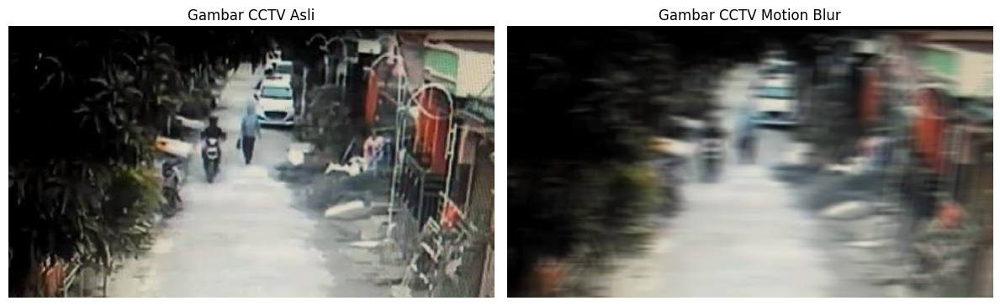

In [2]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# Upload gambar CCTV
uploaded = files.upload()

# Mengambil nama file
filename = next(iter(uploaded))

# Membaca gambar
image = cv2.imread(filename)

if image is None:
    raise ValueError("Gambar tidak berhasil dibaca")

# Membuat efek motion blur
kernel_size = 21
kernel = np.zeros((kernel_size, kernel_size))
kernel[kernel_size // 2, :] = 1
kernel = kernel / kernel.sum()

# Menerapkan blur
blurred = cv2.filter2D(image, -1, kernel)

# Menyimpan gambar rusak
cv2.imwrite("cctv_blur.png", blurred)

# Mengubah warna BGR ke RGB
original_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
blurred_rgb = cv2.cvtColor(blurred, cv2.COLOR_BGR2RGB)

# Menampilkan perbandingan
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_rgb)
plt.title("Gambar CCTV Asli")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(blurred_rgb)
plt.title("Gambar CCTV Motion Blur")
plt.axis("off")

plt.tight_layout()
plt.show()


In [4]:
!pip install -q diffusers transformers accelerate safetensors


In [5]:

import torch
from diffusers import AutoencoderKL

device = "cuda"

# Memuat VAE Stable Diffusion 1.5
vae = AutoencoderKL.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5",
    subfolder="vae",
    torch_dtype=torch.float16
).to(device)

vae.eval()

print("VAE berhasil dimuat!")
print("Device:", device)


RuntimeError: Failed to import diffusers.models.autoencoders.autoencoder_kl because of the following error (look up to see its traceback):
cannot import name 'FqnToConfig' from 'torchao.quantization' (/usr/local/lib/python3.13/dist-packages/torchao/quantization/__init__.py)

In [6]:
!pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [1]:

import torch
from diffusers import AutoencoderKL

device = "cuda" if torch.cuda.is_available() else "cpu"

print("GPU:", torch.cuda.get_device_name(0)
      if device == "cuda" else "CPU")

vae = AutoencoderKL.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5",
    subfolder="vae",
    torch_dtype=torch.float16
).to(device)

vae.eval()

print("VAE berhasil dimuat!")


GPU: Tesla T4


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

vae/diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B /  335MB            

vae/diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

VAE berhasil dimuat!


In [3]:
from google.colab import files
uploaded = files.upload()

Saving cctv_blur.jpg to cctv_blur.jpg


In [4]:

import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Membaca gambar CCTV blur
image = Image.open("cctv_blur.jpg").convert("RGB")

# Mengubah ukuran gambar
image = image.resize((512, 512))

# Mengubah gambar menjadi array
image_array = np.array(image).astype(np.float32) / 255.0

# Mengubah array menjadi tensor
image_tensor = torch.from_numpy(image_array)
image_tensor = image_tensor.permute(2, 0, 1)
image_tensor = image_tensor.unsqueeze(0)

# Normalisasi nilai gambar
image_tensor = image_tensor * 2 - 1

# Memindahkan tensor ke GPU
image_tensor = image_tensor.to(
    "cuda",
    dtype=torch.float16
)

# Proses encoding menggunakan VAE
with torch.no_grad():
    latent = vae.encode(
        image_tensor
    ).latent_dist.mode()

    latent = latent * vae.config.scaling_factor

print("Ukuran gambar:", image_tensor.shape)
print("Ukuran latent:", latent.shape)


Ukuran gambar: torch.Size([1, 3, 512, 512])
Ukuran latent: torch.Size([1, 4, 64, 64])


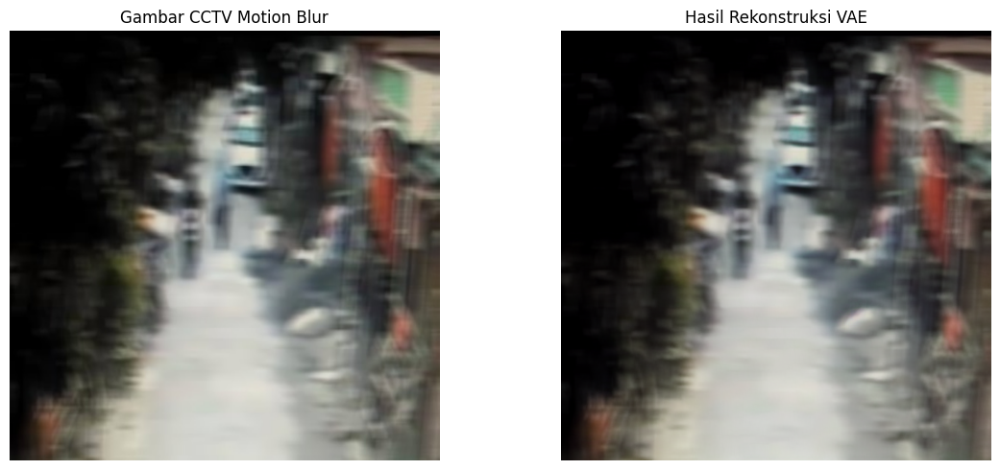

Encoding dan decoding berhasil!


In [5]:

# Mengembalikan latent menjadi gambar
with torch.no_grad():
    reconstructed = vae.decode(
        latent / vae.config.scaling_factor
    ).sample

# Normalisasi hasil
reconstructed = (reconstructed / 2 + 0.5).clamp(0, 1)

# Mengubah tensor menjadi array gambar
reconstructed = reconstructed[0].float().cpu()
reconstructed = reconstructed.permute(1, 2, 0).numpy()

# Menampilkan hasil
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Gambar CCTV Motion Blur")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(reconstructed)
plt.title("Hasil Rekonstruksi VAE")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Encoding dan decoding berhasil!")


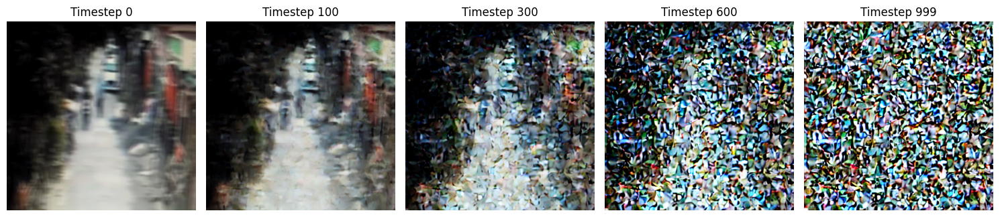

In [6]:

import torch
import matplotlib.pyplot as plt
from diffusers import DDPMScheduler

# Membuat scheduler diffusion
scheduler = DDPMScheduler(
    num_train_timesteps=1000,
    beta_schedule="scaled_linear",
    beta_start=0.00085,
    beta_end=0.012
)

# Menggunakan latent dari VAE sebelumnya
original_latent = latent.clone()

# Membuat Gaussian noise
torch.manual_seed(42)
noise = torch.randn_like(original_latent)

# Menentukan timestep
timesteps = [0, 100, 300, 600, 999]

plt.figure(figsize=(15, 4))

for i, t in enumerate(timesteps):

    # Membuat tensor timestep
    timestep = torch.tensor(
        [t],
        device=original_latent.device
    )

    # Menambahkan noise pada latent
    noisy_latent = scheduler.add_noise(
        original_latent,
        noise,
        timestep
    )

    # Decode latent menjadi gambar
    with torch.no_grad():
        decoded = vae.decode(
            noisy_latent / vae.config.scaling_factor
        ).sample

    # Mengubah tensor menjadi gambar
    decoded = (decoded / 2 + 0.5).clamp(0, 1)
    decoded = decoded[0].float().cpu()
    decoded = decoded.permute(1, 2, 0).numpy()

    # Menampilkan gambar
    plt.subplot(1, 5, i + 1)
    plt.imshow(decoded)
    plt.title(f"Timestep {t}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [7]:

import torch
from diffusers import UNet2DConditionModel

# Membersihkan cache GPU yang tidak digunakan
torch.cuda.empty_cache()

# Memuat U-Net Stable Diffusion 1.5
unet = UNet2DConditionModel.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5",
    subfolder="unet",
    torch_dtype=torch.float16
).to("cuda")

# Menggunakan mode evaluasi
unet.eval()

print("U-Net berhasil dimuat!")
print("Device:", next(unet.parameters()).device)
print("Jumlah parameter:",
      sum(p.numel() for p in unet.parameters()))


config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

unet/diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B / 3.44GB            

unet/diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

U-Net berhasil dimuat!
Device: cuda:0
Jumlah parameter: 859520964


In [8]:

import torch
from transformers import CLIPTokenizer, CLIPTextModel

model_id = "stable-diffusion-v1-5/stable-diffusion-v1-5"

# Memuat tokenizer
tokenizer = CLIPTokenizer.from_pretrained(
    model_id,
    subfolder="tokenizer"
)

# Memuat text encoder
text_encoder = CLIPTextModel.from_pretrained(
    model_id,
    subfolder="text_encoder",
    torch_dtype=torch.float16
).to("cuda")

text_encoder.eval()

# Prompt sederhana untuk conditioning
prompt = "a surveillance camera image of a street"

# Mengubah teks menjadi token
text_input = tokenizer(
    prompt,
    padding="max_length",
    max_length=tokenizer.model_max_length,
    truncation=True,
    return_tensors="pt"
)

# Mengubah token menjadi embeddings
with torch.no_grad():
    text_embeddings = text_encoder(
        text_input.input_ids.to("cuda")
    )[0]

print("Text embeddings berhasil dibuat!")
print("Ukuran embeddings:", text_embeddings.shape)


tokenizer_config.json:   0%|          | 0.00/806 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.06M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/617 [00:00<?, ?B/s]

text_encoder/model.safetensors: reconstructing file:   0%|          |  0.00B /  492MB            

text_encoder/model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Text embeddings berhasil dibuat!
Ukuran embeddings: torch.Size([1, 77, 768])


In [9]:

from diffusers import DDPMScheduler

# Scheduler yang digunakan untuk latihan
scheduler = DDPMScheduler(
    num_train_timesteps=1000,
    beta_schedule="scaled_linear",
    beta_start=0.00085,
    beta_end=0.012
)

# Menggunakan latent CCTV dari tahap sebelumnya
clean_input_latent = latent.detach()

# Membuat noise
noise = torch.randn_like(clean_input_latent)

# Menentukan timestep
timestep = torch.tensor([300], device="cuda")

# Forward diffusion
noisy_latent = scheduler.add_noise(
    clean_input_latent,
    noise,
    timestep
)

# Prediksi noise menggunakan U-Net
with torch.no_grad():
    predicted_noise = unet(
        noisy_latent,
        timestep,
        encoder_hidden_states=text_embeddings
    ).sample

print("Prediksi noise berhasil!")
print("Ukuran noisy latent:", noisy_latent.shape)
print("Ukuran predicted noise:", predicted_noise.shape)


Prediksi noise berhasil!
Ukuran noisy latent: torch.Size([1, 4, 64, 64])
Ukuran predicted noise: torch.Size([1, 4, 64, 64])


In [10]:

import torch
import matplotlib.pyplot as plt

# Menggunakan noisy_latent dan predicted_noise
# dari tahap sebelumnya

# Satu langkah reverse diffusion
with torch.no_grad():
    result = scheduler.step(
        model_output=predicted_noise,
        timestep=300,
        sample=noisy_latent
    )

    previous_latent = result.prev_sample

print("Reverse diffusion berhasil!")
print("Ukuran latent:", previous_latent.shape)


Reverse diffusion berhasil!
Ukuran latent: torch.Size([1, 4, 64, 64])


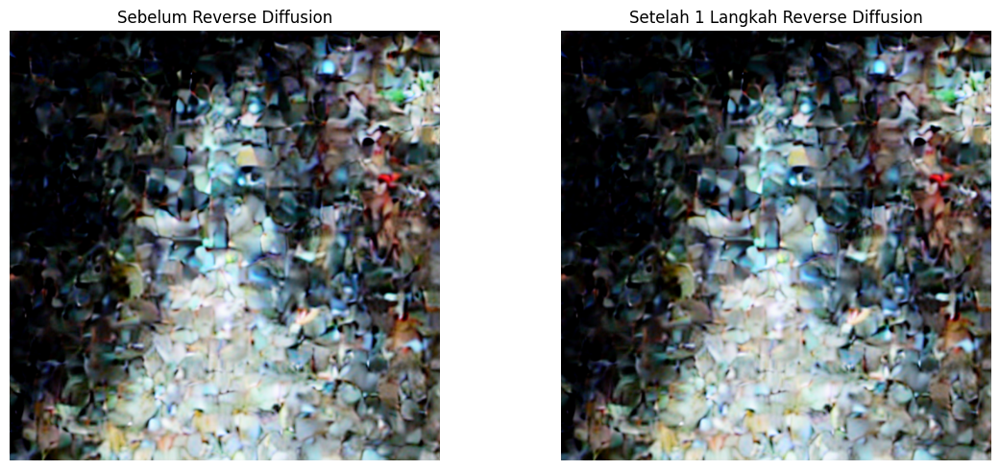

In [11]:

# Decode noisy latent dan previous latent
with torch.no_grad():
    noisy_decoded = vae.decode(
        noisy_latent / vae.config.scaling_factor
    ).sample

    previous_decoded = vae.decode(
        previous_latent / vae.config.scaling_factor
    ).sample

# Fungsi mengubah tensor menjadi gambar
def tensor_to_image(tensor):
    tensor = (tensor / 2 + 0.5).clamp(0, 1)
    tensor = tensor[0].float().cpu()
    return tensor.permute(1, 2, 0).numpy()

noisy_image = tensor_to_image(noisy_decoded)
previous_image = tensor_to_image(previous_decoded)

# Menampilkan perbandingan
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(noisy_image)
plt.title("Sebelum Reverse Diffusion")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(previous_image)
plt.title("Setelah 1 Langkah Reverse Diffusion")
plt.axis("off")

plt.tight_layout()
plt.show()


Reverse diffusion bertahap selesai!


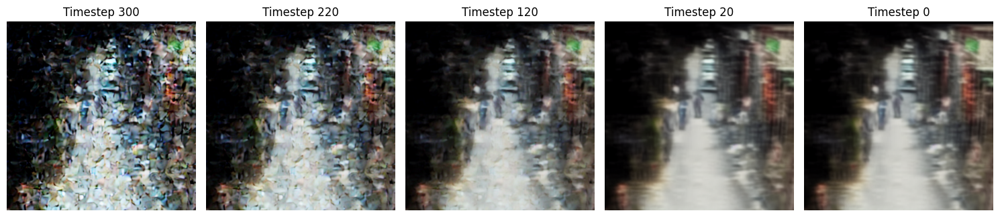

In [12]:

import torch
import matplotlib.pyplot as plt
from diffusers import DDIMScheduler

# Scheduler untuk reverse diffusion
ddim = DDIMScheduler(
    num_train_timesteps=1000,
    beta_start=0.00085,
    beta_end=0.012,
    beta_schedule="scaled_linear",
    clip_sample=False,
    set_alpha_to_one=False
)

# Membuat 50 langkah inference
ddim.set_timesteps(50, device="cuda")

# Memulai dari noisy latent pada timestep 300
start_t = 300

# Pilih timestep inference yang <= 300
selected_timesteps = ddim.timesteps[
    ddim.timesteps <= start_t
]

# Tambahkan noise sesuai timestep awal yang dipilih
t_start = selected_timesteps[0]

torch.manual_seed(42)
noise = torch.randn_like(latent)

current_latent = ddim.add_noise(
    latent,
    noise,
    t_start
)

# Simpan hasil untuk visualisasi
results = []

with torch.no_grad():
    for i, t in enumerate(selected_timesteps):

        # Prediksi noise dengan U-Net
        noise_pred = unet(
            current_latent,
            t,
            encoder_hidden_states=text_embeddings
        ).sample

        # Reverse diffusion
        current_latent = ddim.step(
            noise_pred,
            t,
            current_latent
        ).prev_sample

        # Simpan beberapa hasil
        if i == 0 or (i + 1) % 5 == 0 or i == len(selected_timesteps)-1:
            decoded = vae.decode(
                current_latent / vae.config.scaling_factor
            ).sample

            decoded = (decoded / 2 + 0.5).clamp(0, 1)
            decoded = decoded[0].float().cpu()
            decoded = decoded.permute(1, 2, 0).numpy()

            results.append((int(t.item()), decoded))

print("Reverse diffusion bertahap selesai!")

# Visualisasi beberapa hasil
plt.figure(figsize=(15, 4))

for i, (t, img) in enumerate(results[:5]):
    plt.subplot(1, 5, i + 1)
    plt.imshow(img)
    plt.title(f"Timestep {t}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [13]:
!git ls-remote https://github.com/search?q=BIR-Adapter

fatal: https://github.com/search?q=BIR-Adapter/info/refs not valid: is this a git repository?


In [14]:
from PIL import Image

hasil = Image.fromarray(
    (results[-1][1] * 255).clip(0, 255).astype("uint8")
)

hasil.save("hasil_reverse_diffusion.png")

print("Gambar berhasil disimpan!")

Gambar berhasil disimpan!


In [15]:

import torch
import torch.nn as nn
import torch.nn.functional as F

class RestoringAttention(nn.Module):
    def __init__(self, dim=320):
        super().__init__()

        self.query = nn.Linear(dim, dim, bias=False)
        self.key_adapter = nn.Linear(dim, dim)
        self.value_adapter = nn.Linear(dim, dim)
        self.output_adapter = nn.Linear(dim, dim)

        # Inisialisasi output adapter dengan nol
        nn.init.zeros_(self.output_adapter.weight)
        nn.init.zeros_(self.output_adapter.bias)

    def forward(self, degraded_features, diffusion_features):

        Q = self.query(degraded_features)
        K = self.key_adapter(diffusion_features)
        V = self.value_adapter(diffusion_features)

        attention = F.scaled_dot_product_attention(
            Q.unsqueeze(1),
            K.unsqueeze(1),
            V.unsqueeze(1)
        ).squeeze(1)

        output = self.output_adapter(attention)

        return output


# Membuat adapter
adapter = RestoringAttention(dim=320).to("cuda")

# Contoh fitur untuk pengujian
degraded_features = torch.randn(1, 64, 320, device="cuda")
diffusion_features = torch.randn(1, 64, 320, device="cuda")

# Menjalankan restoring attention
with torch.no_grad():
    output = adapter(
        degraded_features,
        diffusion_features
    )

print("Restoring Attention berhasil dijalankan!")
print("Ukuran output:", output.shape)
print("Jumlah parameter:",
      sum(p.numel() for p in adapter.parameters()))


Restoring Attention berhasil dijalankan!
Ukuran output: torch.Size([1, 64, 320])
Jumlah parameter: 410560


In [16]:

import torch
import torch.nn.functional as F

# 1. Mengambil latent gambar CCTV blur
degraded_latent = latent.detach().float()

# 2. Mengambil latent hasil reverse diffusion
diffusion_latent = current_latent.detach().float()

# 3. Mengubah ukuran latent menjadi 8 x 8
degraded_small = F.adaptive_avg_pool2d(
    degraded_latent, (8, 8)
)

diffusion_small = F.adaptive_avg_pool2d(
    diffusion_latent, (8, 8)
)

# 4. Mengubah latent menjadi urutan fitur
degraded_features = degraded_small.flatten(2).transpose(1, 2)
diffusion_features = diffusion_small.flatten(2).transpose(1, 2)

print("Degraded features:", degraded_features.shape)
print("Diffusion features:", diffusion_features.shape)


Degraded features: torch.Size([1, 64, 4])
Diffusion features: torch.Size([1, 64, 4])


In [17]:

# Membuat adapter sesuai dimensi fitur
adapter_cctv = RestoringAttention(dim=4).to("cuda")

adapter_cctv.eval()

# Menjalankan restoring attention
with torch.no_grad():
    output_cctv = adapter_cctv(
        degraded_features.to("cuda"),
        diffusion_features.to("cuda")
    )

print("Restoring Attention CCTV berhasil!")
print("Ukuran output:", output_cctv.shape)
print("Rata-rata output:", output_cctv.abs().mean().item())


Restoring Attention CCTV berhasil!
Ukuran output: torch.Size([1, 64, 4])
Rata-rata output: 0.0


In [18]:

import torch

# Menyimpan fitur dari U-Net
captured_features = {}

# Fungsi untuk mengambil output layer
def capture_features(module, inputs, output):
    if isinstance(output, tuple):
        feature = output[0]
    else:
        feature = output

    captured_features["unet"] = feature.detach()

# Mengambil fitur dari down block pertama
hook = unet.down_blocks[0].register_forward_hook(
    capture_features
)

# Menjalankan U-Net menggunakan noisy latent
with torch.no_grad():
    _ = unet(
        noisy_latent,
        timestep,
        encoder_hidden_states=text_embeddings
    )

# Menghapus hook setelah selesai
hook.remove()

# Menampilkan ukuran fitur
feature_unet = captured_features["unet"]

print("Fitur U-Net berhasil diambil!")
print("Ukuran fitur:", feature_unet.shape)


Fitur U-Net berhasil diambil!
Ukuran fitur: torch.Size([1, 320, 32, 32])


In [19]:

import torch

# Menyimpan fitur degraded image
captured_degraded = {}

def capture_degraded(module, inputs, output):
    if isinstance(output, tuple):
        feature = output[0]
    else:
        feature = output

    captured_degraded["feature"] = feature.detach()

# Memasang hook pada down block yang sama
hook = unet.down_blocks[0].register_forward_hook(
    capture_degraded
)

# Mengambil latent gambar CCTV rusak
degraded_latent = latent.detach()

# Memproses degraded latent melalui U-Net
with torch.no_grad():
    _ = unet(
        degraded_latent,
        timestep,
        encoder_hidden_states=text_embeddings
    )

# Menghapus hook
hook.remove()

# Menampilkan hasil
degraded_unet_feature = captured_degraded["feature"]

print("Fitur CCTV rusak berhasil diambil!")
print("Ukuran fitur:", degraded_unet_feature.shape)
print("Ukuran fitur diffusion:", feature_unet.shape)


Fitur CCTV rusak berhasil diambil!
Ukuran fitur: torch.Size([1, 320, 32, 32])
Ukuran fitur diffusion: torch.Size([1, 320, 32, 32])


In [20]:

import torch

# Fitur dari gambar CCTV rusak
degraded_features = (
    degraded_unet_feature
    .flatten(2)
    .transpose(1, 2)
    .float()
)

# Fitur dari proses diffusion
diffusion_features = (
    feature_unet
    .flatten(2)
    .transpose(1, 2)
    .float()
)

print("Degraded features:", degraded_features.shape)
print("Diffusion features:", diffusion_features.shape)


Degraded features: torch.Size([1, 1024, 320])
Diffusion features: torch.Size([1, 1024, 320])


In [21]:

# Membuat adapter dengan dimensi 320
adapter_unet = RestoringAttention(dim=320).to("cuda")

adapter_unet.eval()

# Menjalankan Restoring Attention
with torch.no_grad():
    restored_features = adapter_unet(
        degraded_features.to("cuda"),
        diffusion_features.to("cuda")
    )

print("Restoring Attention berhasil!")
print("Ukuran output:", restored_features.shape)
print("Rata-rata output:",
      restored_features.abs().mean().item())


Restoring Attention berhasil!
Ukuran output: torch.Size([1, 1024, 320])
Rata-rata output: 0.0


In [22]:

import torch

# Menggabungkan fitur CCTV dengan output adapter
combined_features = degraded_features + restored_features

print("Fitur CCTV:", degraded_features.shape)
print("Output adapter:", restored_features.shape)
print("Fitur gabungan:", combined_features.shape)

# Mengukur perubahan fitur
difference = (
    combined_features - degraded_features
).abs().mean().item()

print("Rata-rata perubahan fitur:", difference)


Fitur CCTV: torch.Size([1, 1024, 320])
Output adapter: torch.Size([1, 1024, 320])
Fitur gabungan: torch.Size([1, 1024, 320])
Rata-rata perubahan fitur: 0.0


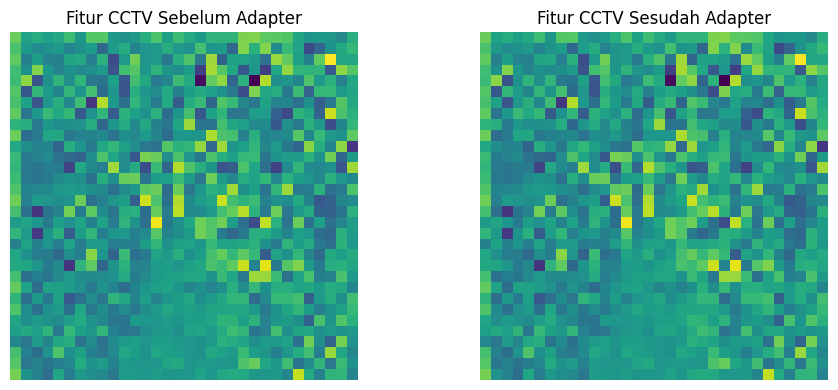

In [23]:

import matplotlib.pyplot as plt

# Mengembalikan format fitur menjadi gambar fitur
before = degraded_features.transpose(1, 2).reshape(1, 320, 32, 32)
after = combined_features.transpose(1, 2).reshape(1, 320, 32, 32)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(before[0, 0].detach().cpu().numpy(), cmap="viridis")
plt.title("Fitur CCTV Sebelum Adapter")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(after[0, 0].detach().cpu().numpy(), cmap="viridis")
plt.title("Fitur CCTV Sesudah Adapter")
plt.axis("off")

plt.tight_layout()
plt.show()


Gambar asli tersedia: True
Gambar blur tersedia: True


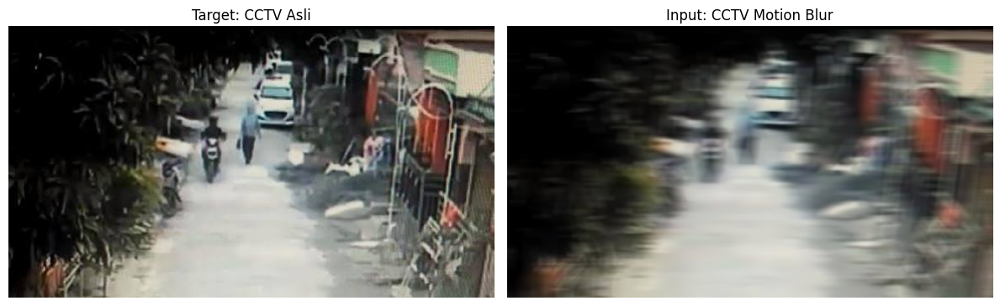

Pasangan data training siap!


In [24]:

import cv2
import os
import matplotlib.pyplot as plt

print("Gambar asli tersedia:", os.path.exists("cctv.jpg"))
print("Gambar blur tersedia:", os.path.exists("cctv_blur.png"))

original = cv2.imread("cctv.jpg")
blurred = cv2.imread("cctv_blur.png")

if original is None or blurred is None:
    print("File belum lengkap. Upload kembali gambar CCTV.")
else:
    original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)
    blurred = cv2.cvtColor(blurred, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(original)
    plt.title("Target: CCTV Asli")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(blurred)
    plt.title("Input: CCTV Motion Blur")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    print("Pasangan data training siap!")


In [25]:

import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torchvision.transforms as transforms

class CCTVDataset(Dataset):
    def __init__(self):
        self.transform = transforms.Compose([
            transforms.Resize((512, 512)),
            transforms.ToTensor()
        ])

        self.pairs = [
            ("cctv_blur.jpg", "cctv.jpg")
        ]

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        blur_path, clean_path = self.pairs[idx]

        blur = Image.open(blur_path).convert("RGB")
        clean = Image.open(clean_path).convert("RGB")

        blur = self.transform(blur)
        clean = self.transform(clean)

        return {
            "blur": blur,
            "clean": clean
        }

dataset = CCTVDataset()

dataloader = DataLoader(
    dataset,
    batch_size=1,
    shuffle=True
)

print("Dataset berhasil dibuat!")
print("Jumlah pasangan gambar:", len(dataset))

batch = next(iter(dataloader))

print("Ukuran gambar blur:", batch["blur"].shape)
print("Ukuran gambar asli:", batch["clean"].shape)


Dataset berhasil dibuat!
Jumlah pasangan gambar: 1
Ukuran gambar blur: torch.Size([1, 3, 512, 512])
Ukuran gambar asli: torch.Size([1, 3, 512, 512])


In [26]:

import torch

# Mengambil satu batch dari dataset
batch = next(iter(dataloader))

# Mengubah rentang piksel [0, 1] menjadi [-1, 1]
blur_image = batch["blur"].to(
    device="cuda", dtype=torch.float16
) * 2 - 1

clean_image = batch["clean"].to(
    device="cuda", dtype=torch.float16
) * 2 - 1

# Menggunakan VAE yang sudah dimuat sebelumnya
vae.eval()

with torch.no_grad():
    blur_latent = (
        vae.encode(blur_image).latent_dist.mode()
        * vae.config.scaling_factor
    )

    clean_latent = (
        vae.encode(clean_image).latent_dist.mode()
        * vae.config.scaling_factor
    )

print("Encoding VAE berhasil!")
print("Ukuran latent CCTV blur:", blur_latent.shape)
print("Ukuran latent CCTV asli:", clean_latent.shape)


Encoding VAE berhasil!
Ukuran latent CCTV blur: torch.Size([1, 4, 64, 64])
Ukuran latent CCTV asli: torch.Size([1, 4, 64, 64])


In [27]:

import torch.nn.functional as F

# Menghitung Mean Squared Error
latent_mse = F.mse_loss(
    blur_latent.float(),
    clean_latent.float()
)

print("MSE antara latent blur dan asli:", latent_mse.item())


MSE antara latent blur dan asli: 0.4355153441429138


In [28]:

import torch
import torch.nn as nn
import torch.nn.functional as F

# Menggunakan kelas RestoringAttention dari tahap sebelumnya
adapter_train = RestoringAttention(dim=4).to("cuda").float()

# Membekukan parameter VAE dan U-Net
vae.requires_grad_(False)
unet.requires_grad_(False)

# Menyiapkan optimizer
optimizer = torch.optim.Adam(
    adapter_train.parameters(),
    lr=0.001
)

# Mengubah latent menjadi format attention
blur_features = (
    blur_latent.detach()
    .float()
    .flatten(2)
    .transpose(1, 2)
)

clean_features = (
    clean_latent.detach()
    .float()
    .flatten(2)
    .transpose(1, 2)
)

print("Adapter training siap!")
print("Input:", blur_features.shape)
print("Target:", clean_features.shape)


Adapter training siap!
Input: torch.Size([1, 4096, 4])
Target: torch.Size([1, 4096, 4])


In [29]:

# Mengubah ukuran latent menjadi 16x16
blur_small = F.adaptive_avg_pool2d(
    blur_latent.detach().float(), (16, 16)
)

clean_small = F.adaptive_avg_pool2d(
    clean_latent.detach().float(), (16, 16)
)

x = blur_small.flatten(2).transpose(1, 2)
target = clean_small.flatten(2).transpose(1, 2)

adapter_train.train()

for epoch in range(1, 51):
    optimizer.zero_grad()

    # Adapter mempelajari koreksi residual
    correction = adapter_train(x, x)
    prediction = x + correction

    loss = F.mse_loss(prediction, target)

    loss.backward()
    optimizer.step()

    if epoch == 1 or epoch % 10 == 0:
        print(f"Epoch {epoch:02d} | Loss: {loss.item():.6f}")

print("Training selesai!")


Epoch 01 | Loss: 0.056189
Epoch 10 | Loss: 0.049072
Epoch 20 | Loss: 0.042440
Epoch 30 | Loss: 0.037911
Epoch 40 | Loss: 0.035556
Epoch 50 | Loss: 0.034355
Training selesai!


MSE sebelum adapter: 0.05618927627801895
MSE sesudah adapter: 0.03425893187522888


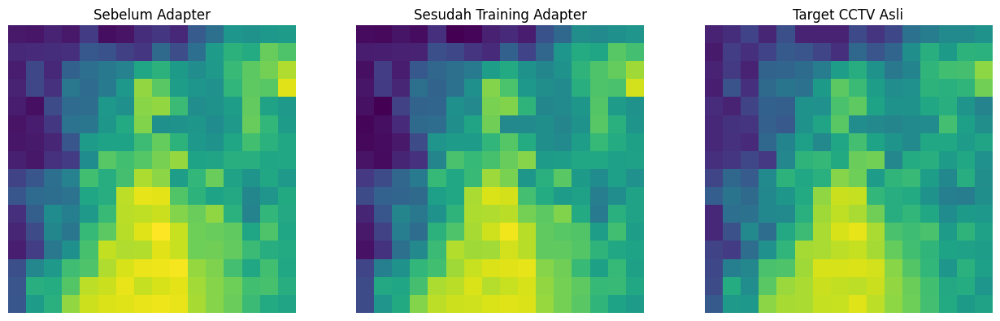

In [30]:

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

adapter_train.eval()

with torch.no_grad():
    # Prediksi setelah training
    correction = adapter_train(x, x)
    prediction = x + correction

    # Menghitung MSE sebelum dan sesudah
    mse_before = F.mse_loss(x, target).item()
    mse_after = F.mse_loss(prediction, target).item()

print("MSE sebelum adapter:", mse_before)
print("MSE sesudah adapter:", mse_after)

# Mengubah fitur kembali menjadi feature map
before_map = x.transpose(1, 2).reshape(1, 4, 16, 16)
after_map = prediction.transpose(1, 2).reshape(1, 4, 16, 16)
target_map = target.transpose(1, 2).reshape(1, 4, 16, 16)

# Visualisasi channel pertama
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

images = [
    before_map[0, 0],
    after_map[0, 0],
    target_map[0, 0]
]

titles = [
    "Sebelum Adapter",
    "Sesudah Training Adapter",
    "Target CCTV Asli"
]

# Menggunakan skala warna yang sama
vmin = min(img.min().item() for img in images)
vmax = max(img.max().item() for img in images)

for ax, img, title in zip(axes, images, titles):
    ax.imshow(
        img.detach().cpu().numpy(),
        cmap="viridis",
        vmin=vmin,
        vmax=vmax
    )
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [31]:

import torch
import torch.nn.functional as F

adapter_train.eval()

with torch.no_grad():
    # Mengambil latent blur resolusi penuh
    full_blur = blur_latent.detach().float()

    # Mengambil latent resolusi kecil
    small_blur = F.adaptive_avg_pool2d(full_blur, (16, 16))
    small_features = small_blur.flatten(2).transpose(1, 2)

    # Menghasilkan koreksi dari adapter
    correction = adapter_train(small_features, small_features)

    # Mengubah koreksi ke bentuk spasial
    correction_map = correction.transpose(1, 2).reshape(1, 4, 16, 16)

    # Memperbesar koreksi menjadi 64 x 64
    correction_full = F.interpolate(
        correction_map,
        size=(64, 64),
        mode="bilinear",
        align_corners=False
    )

    # Menambahkan koreksi pada latent blur
    restored_latent = full_blur + correction_full

print("Latent sebelum:", full_blur.shape)
print("Latent sesudah:", restored_latent.shape)


Latent sebelum: torch.Size([1, 4, 64, 64])
Latent sesudah: torch.Size([1, 4, 64, 64])


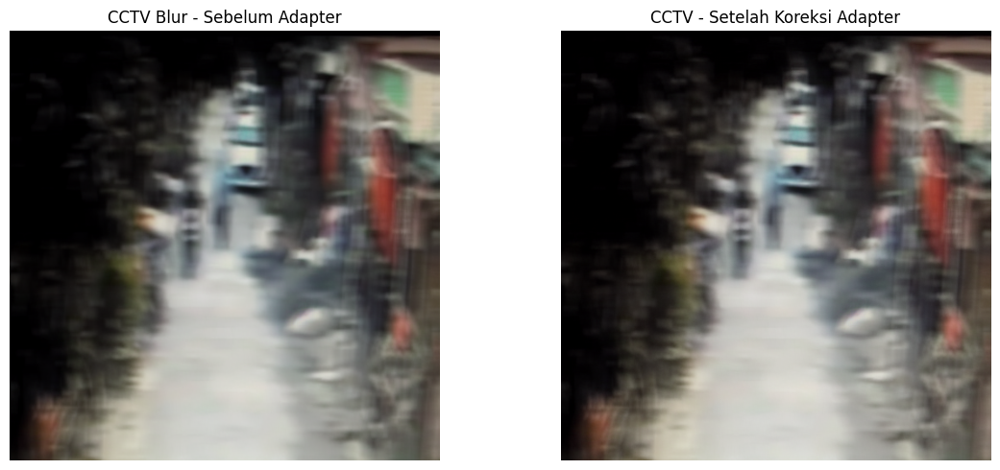

In [32]:

import matplotlib.pyplot as plt

vae.eval()

with torch.no_grad():
    # Decode latent blur
    before_image = vae.decode(
        (full_blur / vae.config.scaling_factor).to(
            device="cuda", dtype=torch.float16
        )
    ).sample

    # Decode latent setelah koreksi
    after_image = vae.decode(
        (restored_latent / vae.config.scaling_factor).to(
            device="cuda", dtype=torch.float16
        )
    ).sample

def to_image(tensor):
    return (
        (tensor.squeeze(0).float().cpu().permute(1, 2, 0) + 1) / 2
    ).clamp(0, 1).numpy()

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(to_image(before_image))
plt.title("CCTV Blur - Sebelum Adapter")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(to_image(after_image))
plt.title("CCTV - Setelah Koreksi Adapter")
plt.axis("off")

plt.tight_layout()
plt.show()


In [33]:

import numpy as np
from skimage.metrics import peak_signal_noise_ratio
from skimage.metrics import structural_similarity

# Mengubah output VAE menjadi array RGB [0, 1]
before_np = to_image(before_image)
after_np = to_image(after_image)

# Menggunakan target CCTV asli dengan ukuran yang sama
clean_np = (
    batch["clean"][0]
    .permute(1, 2, 0)
    .cpu()
    .numpy()
)

# Menghitung PSNR
psnr_before = peak_signal_noise_ratio(
    clean_np, before_np, data_range=1.0
)

psnr_after = peak_signal_noise_ratio(
    clean_np, after_np, data_range=1.0
)

# Menghitung SSIM
ssim_before = structural_similarity(
    clean_np, before_np,
    channel_axis=2, data_range=1.0
)

ssim_after = structural_similarity(
    clean_np, after_np,
    channel_axis=2, data_range=1.0
)

print("=== HASIL EVALUASI CCTV ===")
print(f"PSNR sebelum adapter : {psnr_before:.4f} dB")
print(f"PSNR sesudah adapter : {psnr_after:.4f} dB")
print(f"SSIM sebelum adapter : {ssim_before:.4f}")
print(f"SSIM sesudah adapter : {ssim_after:.4f}")


=== HASIL EVALUASI CCTV ===
PSNR sebelum adapter : 23.3761 dB
PSNR sesudah adapter : 23.3537 dB
SSIM sebelum adapter : 0.6451
SSIM sesudah adapter : 0.6373


=== EVALUASI UNSHARP MASKING ===
PSNR Blur      : 23.4544 dB
PSNR Sharpened : 23.4255 dB
SSIM Blur      : 0.6468
SSIM Sharpened : 0.6427


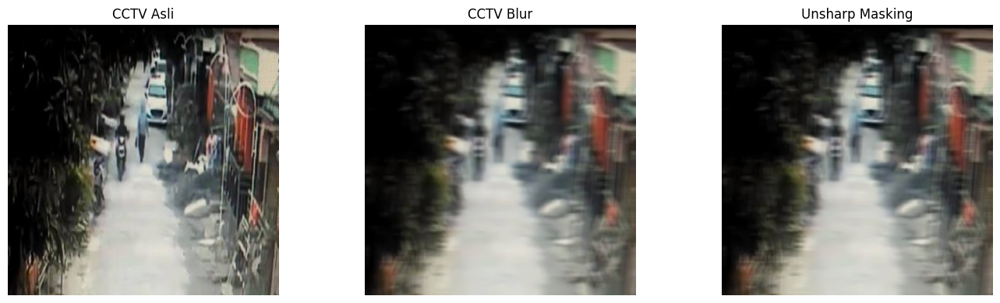

In [34]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

from skimage.metrics import (
    peak_signal_noise_ratio,
    structural_similarity
)

# Mengambil gambar CCTV blur
blur_img = cv2.imread("cctv_blur.png")
clean_img = cv2.imread("cctv.jpg")

# Mengubah ke RGB
blur_img = cv2.cvtColor(blur_img, cv2.COLOR_BGR2RGB)
clean_img = cv2.cvtColor(clean_img, cv2.COLOR_BGR2RGB)

# Menyamakan ukuran
blur_img = cv2.resize(blur_img, (512, 512))
clean_img = cv2.resize(clean_img, (512, 512))

# Unsharp masking
gaussian = cv2.GaussianBlur(blur_img, (0, 0), 2.0)

sharpened = cv2.addWeighted(
    blur_img, 1.5,
    gaussian, -0.5,
    0
)

# Evaluasi
psnr_blur = peak_signal_noise_ratio(
    clean_img, blur_img, data_range=255
)

psnr_sharp = peak_signal_noise_ratio(
    clean_img, sharpened, data_range=255
)

ssim_blur = structural_similarity(
    clean_img, blur_img,
    channel_axis=2, data_range=255
)

ssim_sharp = structural_similarity(
    clean_img, sharpened,
    channel_axis=2, data_range=255
)

print("=== EVALUASI UNSHARP MASKING ===")
print(f"PSNR Blur      : {psnr_blur:.4f} dB")
print(f"PSNR Sharpened : {psnr_sharp:.4f} dB")
print(f"SSIM Blur      : {ssim_blur:.4f}")
print(f"SSIM Sharpened : {ssim_sharp:.4f}")

# Visualisasi
plt.figure(figsize=(14, 4))

for i, (img, title) in enumerate([
    (clean_img, "CCTV Asli"),
    (blur_img, "CCTV Blur"),
    (sharpened, "Unsharp Masking")
]):
    plt.subplot(1, 3, i + 1)
    plt.imshow(img)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()


=== HASIL WIENER DECONVOLUTION ===
PSNR Wiener : 17.4219 dB
SSIM Wiener : 0.3650


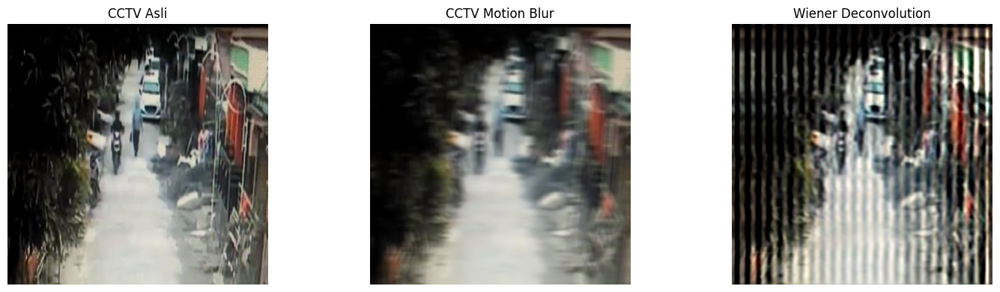

In [35]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.restoration import wiener
from skimage.metrics import (
    peak_signal_noise_ratio,
    structural_similarity
)

# Membaca gambar
blur_img = cv2.cvtColor(
    cv2.imread("cctv_blur.png"),
    cv2.COLOR_BGR2RGB
)

clean_img = cv2.cvtColor(
    cv2.imread("cctv.jpg"),
    cv2.COLOR_BGR2RGB
)

# Menyamakan ukuran
blur_img = cv2.resize(blur_img, (512, 512))
clean_img = cv2.resize(clean_img, (512, 512))

# Membuat kernel motion blur horizontal
kernel_size = 21
kernel = np.zeros((kernel_size, kernel_size), dtype=np.float32)
kernel[kernel_size // 2, :] = 1.0 / kernel_size

# Normalisasi gambar
blur_float = blur_img.astype(np.float32) / 255.0

# Wiener deconvolution per channel
restored_channels = []

for channel in range(3):
    restored_channel = wiener(
        blur_float[:, :, channel],
        kernel,
        balance=0.1,
        clip=True
    )
    restored_channels.append(restored_channel)

restored = np.stack(restored_channels, axis=2)
restored_uint8 = (np.clip(restored, 0, 1) * 255).astype(np.uint8)

# Evaluasi
psnr_wiener = peak_signal_noise_ratio(
    clean_img, restored_uint8, data_range=255
)

ssim_wiener = structural_similarity(
    clean_img, restored_uint8,
    channel_axis=2, data_range=255
)

print("=== HASIL WIENER DECONVOLUTION ===")
print(f"PSNR Wiener : {psnr_wiener:.4f} dB")
print(f"SSIM Wiener : {ssim_wiener:.4f}")

# Visualisasi
plt.figure(figsize=(15, 4))

for i, (img, title) in enumerate([
    (clean_img, "CCTV Asli"),
    (blur_img, "CCTV Motion Blur"),
    (restored_uint8, "Wiener Deconvolution")
]):
    plt.subplot(1, 3, i + 1)
    plt.imshow(img)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()


Baseline Blur: PSNR=23.1210, SSIM=0.6354
Balance=0.01: PSNR=13.2759, SSIM=0.2217
Balance=0.1: PSNR=17.9337, SSIM=0.4135
Balance=1.0: PSNR=22.1629, SSIM=0.6266


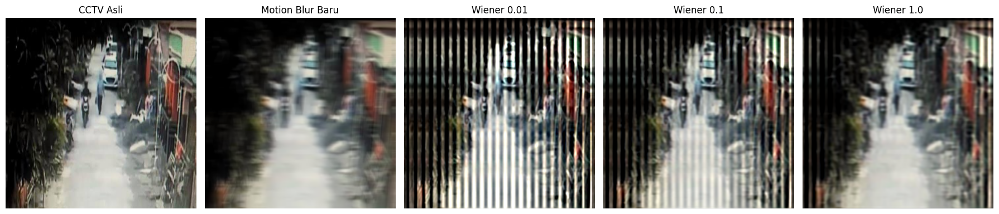

In [36]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.restoration import wiener
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

# Membaca gambar asli dan resize terlebih dahulu
clean = cv2.cvtColor(
    cv2.imread("cctv.jpg"), cv2.COLOR_BGR2RGB
)
clean = cv2.resize(clean, (512, 512))

# Membuat kernel motion blur horizontal
k = 21
kernel = np.zeros((k, k), dtype=np.float32)
kernel[k // 2, :] = 1.0 / k

# Membuat blur baru pada resolusi yang sama
blur = cv2.filter2D(clean, -1, kernel)

# Melakukan Wiener dengan beberapa nilai balance
blur_float = blur.astype(np.float32) / 255.0

results = []

for balance in [0.01, 0.1, 1.0]:
    channels = [
        wiener(
            blur_float[:, :, c],
            kernel,
            balance=balance,
            clip=True
        )
        for c in range(3)
    ]

    restored = np.stack(channels, axis=2)
    restored = (np.clip(restored, 0, 1) * 255).astype(np.uint8)

    psnr = peak_signal_noise_ratio(
        clean, restored, data_range=255
    )
    ssim = structural_similarity(
        clean, restored, channel_axis=2, data_range=255
    )

    results.append((balance, restored, psnr, ssim))

# Metrik gambar blur sebagai baseline
psnr_blur = peak_signal_noise_ratio(clean, blur, data_range=255)
ssim_blur = structural_similarity(
    clean, blur, channel_axis=2, data_range=255
)

print(f"Baseline Blur: PSNR={psnr_blur:.4f}, SSIM={ssim_blur:.4f}")

for balance, _, psnr, ssim in results:
    print(
        f"Balance={balance}: "
        f"PSNR={psnr:.4f}, SSIM={ssim:.4f}"
    )

# Menampilkan hasil
fig, axes = plt.subplots(1, 5, figsize=(18, 4))

images = [clean, blur] + [r[1] for r in results]
titles = [
    "CCTV Asli",
    "Motion Blur Baru",
    "Wiener 0.01",
    "Wiener 0.1",
    "Wiener 1.0"
]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


Iterasi 5: PSNR=23.0919, SSIM=0.7032
Iterasi 10: PSNR=22.1828, SSIM=0.7327
Iterasi 20: PSNR=21.4658, SSIM=0.7639


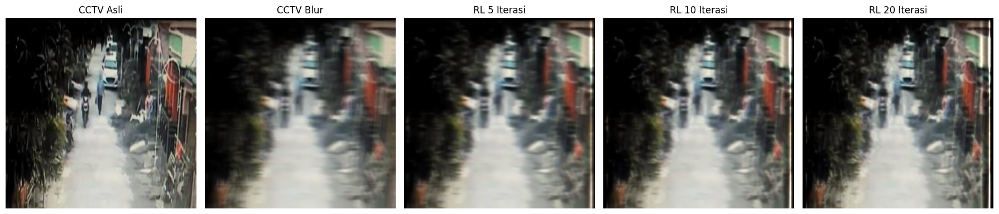

In [37]:

import numpy as np
import matplotlib.pyplot as plt

from skimage.restoration import richardson_lucy
from skimage.metrics import (
    peak_signal_noise_ratio,
    structural_similarity
)

# Menggunakan clean, blur, dan kernel dari Tahap 24
blur_float = blur.astype(np.float32) / 255.0

results_rl = []

# Mencoba beberapa jumlah iterasi
for iterations in [5, 10, 20]:

    channels = []

    for c in range(3):
        restored_channel = richardson_lucy(
            blur_float[:, :, c],
            kernel,
            num_iter=iterations,
            clip=True
        )

        channels.append(restored_channel)

    restored = np.stack(channels, axis=2)
    restored = (
        np.clip(restored, 0, 1) * 255
    ).astype(np.uint8)

    psnr = peak_signal_noise_ratio(
        clean, restored, data_range=255
    )

    ssim = structural_similarity(
        clean, restored,
        channel_axis=2,
        data_range=255
    )

    results_rl.append(
        (iterations, restored, psnr, ssim)
    )

    print(
        f"Iterasi {iterations}: "
        f"PSNR={psnr:.4f}, SSIM={ssim:.4f}"
    )

# Visualisasi
fig, axes = plt.subplots(1, 5, figsize=(18, 4))

images = [clean, blur] + [r[1] for r in results_rl]

titles = [
    "CCTV Asli",
    "CCTV Blur",
    "RL 5 Iterasi",
    "RL 10 Iterasi",
    "RL 20 Iterasi"
]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [38]:

# Tahap 26: Memeriksa self-attention U-Net

from diffusers.models.attention_processor import Attention

self_attention_layers = []

for name, module in unet.named_modules():
    if isinstance(module, Attention) and name.endswith("attn1"):
        self_attention_layers.append((name, module))

print("Jumlah self-attention layer:",
      len(self_attention_layers))

print("\nContoh 5 layer pertama:")
for name, module in self_attention_layers[:5]:
    print(name)
    print("Query dimension:", module.to_q.in_features)
    print("Key dimension:", module.to_k.in_features)
    print("---")


Jumlah self-attention layer: 16

Contoh 5 layer pertama:
down_blocks.0.attentions.0.transformer_blocks.0.attn1
Query dimension: 320
Key dimension: 320
---
down_blocks.0.attentions.1.transformer_blocks.0.attn1
Query dimension: 320
Key dimension: 320
---
down_blocks.1.attentions.0.transformer_blocks.0.attn1
Query dimension: 640
Key dimension: 640
---
down_blocks.1.attentions.1.transformer_blocks.0.attn1
Query dimension: 640
Key dimension: 640
---
down_blocks.2.attentions.0.transformer_blocks.0.attn1
Query dimension: 1280
Key dimension: 1280
---


In [39]:

# Mengambil self-attention pertama
attention = self_attention_layers[0][1]

print("=== STRUKTUR SELF-ATTENTION ===")

print("Query projection:")
print(attention.to_q)

print("\nKey projection:")
print(attention.to_k)

print("\nValue projection:")
print(attention.to_v)

print("\nOutput projection:")
print(attention.to_out[0])

print("\nJumlah attention heads:", attention.heads)
print("Dimensi query:", attention.to_q.out_features)


=== STRUKTUR SELF-ATTENTION ===
Query projection:
Linear(in_features=320, out_features=320, bias=False)

Key projection:
Linear(in_features=320, out_features=320, bias=False)

Value projection:
Linear(in_features=320, out_features=320, bias=False)

Output projection:
Linear(in_features=320, out_features=320, bias=True)

Jumlah attention heads: 8
Dimensi query: 320


In [40]:

import torch
import torch.nn as nn
import torch.nn.functional as F

class BIRRestoringAttention(nn.Module):
    def __init__(self, attention_layer):
        super().__init__()

        dim = attention_layer.to_q.in_features
        inner_dim = attention_layer.to_q.out_features

        self.heads = attention_layer.heads
        self.head_dim = inner_dim // self.heads

        # Proyeksi tambahan untuk fitur degraded
        self.key_adapter = nn.Linear(dim, inner_dim, bias=False)
        self.value_adapter = nn.Linear(dim, inner_dim, bias=False)

        # Proyeksi output tambahan
        self.output_adapter = nn.Linear(inner_dim, dim)

        # Output awal bernilai nol
        nn.init.zeros_(self.output_adapter.weight)
        nn.init.zeros_(self.output_adapter.bias)

    def forward(self, query, degraded_features):

        batch, tokens, channels = query.shape

        K = self.key_adapter(degraded_features)
        V = self.value_adapter(degraded_features)

        def split_heads(x):
            return x.reshape(
                batch, -1, self.heads, self.head_dim
            ).transpose(1, 2)

        Q = split_heads(query)
        K = split_heads(K)
        V = split_heads(V)

        output = F.scaled_dot_product_attention(Q, K, V)

        output = output.transpose(1, 2).reshape(
            batch, tokens, -1
        )

        return self.output_adapter(output)


# Mengambil attention layer pertama
attention_layer = self_attention_layers[0][1]

# Membuat modul adapter
bir_adapter = BIRRestoringAttention(
    attention_layer
).to("cuda", dtype=torch.float32)

print("Modul Restoring Attention berhasil dibuat!")
print("Jumlah parameter:",
      sum(p.numel() for p in bir_adapter.parameters()))


Modul Restoring Attention berhasil dibuat!
Jumlah parameter: 307520


In [41]:

# Menggunakan fitur contoh dengan dimensi 320
query = torch.randn(1, 64, 320, device="cuda")
degraded = torch.randn(1, 64, 320, device="cuda")

with torch.no_grad():
    output = bir_adapter(query, degraded)

print("Restoring Attention berhasil dijalankan!")
print("Ukuran output:", output.shape)
print("Rata-rata output:", output.abs().mean().item())


Restoring Attention berhasil dijalankan!
Ukuran output: torch.Size([1, 64, 320])
Rata-rata output: 0.0


In [42]:

import torch

# Menggunakan self-attention pertama
attention_layer = self_attention_layers[0][1]

# Mengambil fitur U-Net dari Tahap 12
# Bentuk awal: [1, 320, 32, 32]
diffusion_input = (
    feature_unet.detach()
    .flatten(2)
    .transpose(1, 2)
)

degraded_input = (
    degraded_unet_feature.detach()
    .flatten(2)
    .transpose(1, 2)
)

# Memastikan tipe data sesuai bobot attention U-Net
device = attention_layer.to_q.weight.device
dtype = attention_layer.to_q.weight.dtype

diffusion_input = diffusion_input.to(device=device, dtype=dtype)
degraded_input = degraded_input.to(device=device, dtype=dtype)

# Mengambil Query dari proyeksi U-Net yang dibekukan
with torch.no_grad():
    query_unet = attention_layer.to_q(diffusion_input)

print("Query asli U-Net berhasil diambil!")
print("Query:", query_unet.shape)
print("Fitur degraded:", degraded_input.shape)


Query asli U-Net berhasil diambil!
Query: torch.Size([1, 1024, 320])
Fitur degraded: torch.Size([1, 1024, 320])


In [43]:

# Menyesuaikan tipe data adapter dengan Query U-Net
bir_adapter = bir_adapter.to(
    device=device,
    dtype=dtype
)

bir_adapter.eval()

with torch.no_grad():
    adapter_output = bir_adapter(
        query_unet,
        degraded_input
    )

print("Restoring Attention dengan Query U-Net berhasil!")
print("Ukuran output:", adapter_output.shape)
print(
    "Rata-rata output:",
    adapter_output.float().abs().mean().item()
)


Restoring Attention dengan Query U-Net berhasil!
Ukuran output: torch.Size([1, 1024, 320])
Rata-rata output: 0.0


In [44]:

import torch
import torch.nn as nn
import torch.nn.functional as F

class BIRRestoringAttentionV2(nn.Module):
    def __init__(self, attention_layer):
        super().__init__()

        dim = attention_layer.to_q.in_features
        inner_dim = attention_layer.to_q.out_features

        self.heads = attention_layer.heads
        self.head_dim = inner_dim // self.heads

        # Parameter baru yang dapat dilatih
        self.key_adapter = nn.Linear(dim, inner_dim, bias=False)
        self.value_adapter = nn.Linear(dim, inner_dim, bias=False)
        self.output_adapter = nn.Linear(inner_dim, dim)

        # Keluaran awal nol
        nn.init.zeros_(self.output_adapter.weight)
        nn.init.zeros_(self.output_adapter.bias)

    def forward(self, degraded_query, diffusion_features):
        batch = degraded_query.shape[0]

        K = self.key_adapter(diffusion_features)
        V = self.value_adapter(diffusion_features)

        def split_heads(tensor):
            return tensor.reshape(
                batch, -1, self.heads, self.head_dim
            ).transpose(1, 2)

        Q = split_heads(degraded_query)
        K = split_heads(K)
        V = split_heads(V)

        result = F.scaled_dot_product_attention(Q, K, V)

        result = result.transpose(1, 2).reshape(
            batch, -1, self.heads * self.head_dim
        )

        return self.output_adapter(result)


attention_layer = self_attention_layers[0][1]

bir_adapter_v2 = BIRRestoringAttentionV2(
    attention_layer
).to(device="cuda", dtype=torch.float16)

print("Adapter versi 2 berhasil dibuat!")
print(
    "Jumlah parameter:",
    sum(p.numel() for p in bir_adapter_v2.parameters())
)


Adapter versi 2 berhasil dibuat!
Jumlah parameter: 307520


In [45]:

# Query dari fitur CCTV rusak
with torch.no_grad():
    degraded_query = attention_layer.to_q(degraded_input)

# Key dan Value akan dihitung dari fitur diffusion
with torch.no_grad():
    output_v2 = bir_adapter_v2(
        degraded_query,
        diffusion_input
    )

print("Pengujian Restoring Attention berhasil!")
print("Ukuran output:", output_v2.shape)
print("Rata-rata output:", output_v2.float().abs().mean().item())


Pengujian Restoring Attention berhasil!
Ukuran output: torch.Size([1, 1024, 320])
Rata-rata output: 0.0


In [46]:

import torch

# Mengambil layer self-attention pertama
attention_layer = self_attention_layers[0][1]

# Menggunakan fitur diffusion dari tahap sebelumnya
reference_features = diffusion_input.detach()

# Menyimpan status pemanggilan
hook_status = {"called": False}

def bir_attention_hook(module, inputs, output):
    hidden_states = inputs[0]

    # U-Net menggunakan hidden states dengan format [B, N, C]
    if hidden_states.ndim != 3:
        raise ValueError(
            f"Format fitur tidak sesuai: {hidden_states.shape}"
        )

    # Menggunakan Query asli U-Net
    query = module.to_q(hidden_states)

    # Referensi fitur diffusion yang sudah disiapkan
    reference = reference_features.to(
        device=hidden_states.device,
        dtype=hidden_states.dtype
    )

    # Menjalankan adapter
    correction = bir_adapter_v2(query, reference)

    hook_status["called"] = True

    # Menggabungkan output attention asli dengan adapter
    return output + correction


# Memasang hook
bir_hook = attention_layer.register_forward_hook(
    bir_attention_hook
)

print("Hook BIR-Adapter berhasil dipasang!")


Hook BIR-Adapter berhasil dipasang!


In [47]:

try:
    hook_status["called"] = False

    with torch.no_grad():
        test_output = unet(
            noisy_latent,
            timestep,
            encoder_hidden_states=text_embeddings
        ).sample

    print("Forward U-Net berhasil!")
    print("Ukuran output:", test_output.shape)
    print("Adapter dipanggil:", hook_status["called"])

finally:
    # Menghapus hook agar tidak mengganggu eksperimen lain
    bir_hook.remove()
    print("Hook sudah dilepas.")


Forward U-Net berhasil!
Ukuran output: torch.Size([1, 4, 64, 64])
Adapter dipanggil: True
Hook sudah dilepas.


In [48]:

import torch

unet.eval()
bir_adapter_v2.eval()

# Pastikan hook dari tahap sebelumnya sudah dilepas
# Jangan jalankan sel pemasangan hook Tahap 31 lagi sebelum pengujian ini.

# 1. Output U-Net tanpa adapter
with torch.no_grad():
    output_original = unet(
        noisy_latent,
        timestep,
        encoder_hidden_states=text_embeddings
    ).sample.detach().float()

# 2. Memasang adapter sementara
hook_status["called"] = False

test_hook = attention_layer.register_forward_hook(
    bir_attention_hook
)

try:
    with torch.no_grad():
        output_with_adapter = unet(
            noisy_latent,
            timestep,
            encoder_hidden_states=text_embeddings
        ).sample.detach().float()
finally:
    test_hook.remove()

# 3. Mengukur perbedaan
difference = (
    output_original - output_with_adapter
).abs()

print("=== HASIL PENGUJIAN ===")
print("Adapter dipanggil:", hook_status["called"])
print("Ukuran output asli:", output_original.shape)
print("Ukuran output adapter:", output_with_adapter.shape)
print("Rata-rata perbedaan:", difference.mean().item())
print("Perbedaan maksimum:", difference.max().item())


=== HASIL PENGUJIAN ===
Adapter dipanggil: True
Ukuran output asli: torch.Size([1, 4, 64, 64])
Ukuran output adapter: torch.Size([1, 4, 64, 64])
Rata-rata perbedaan: 0.0
Perbedaan maksimum: 0.0


In [49]:

import torch
import torch.nn.functional as F

# Membekukan backbone U-Net
unet.requires_grad_(False)
unet.eval()

# Mengaktifkan training pada adapter
bir_adapter_v2.requires_grad_(True)
bir_adapter_v2.train()

# Gunakan FP32 untuk parameter adapter agar training stabil
bir_adapter_v2 = bir_adapter_v2.float()

optimizer_bir = torch.optim.Adam(
    bir_adapter_v2.parameters(),
    lr=1e-4
)

print("U-Net trainable parameters:",
      sum(p.numel() for p in unet.parameters() if p.requires_grad))

print("Adapter trainable parameters:",
      sum(p.numel() for p in bir_adapter_v2.parameters() if p.requires_grad))


U-Net trainable parameters: 0
Adapter trainable parameters: 307520


In [50]:

# Query dari U-Net yang dibekukan
with torch.no_grad():
    degraded_query = attention_layer.to_q(
        degraded_input.to(
            device=attention_layer.to_q.weight.device,
            dtype=attention_layer.to_q.weight.dtype
        )
    ).detach().float()

# Fitur diffusion
diffusion_train = diffusion_input.detach().float()

# Target percobaan: koreksi kecil yang bukan nol
# Ini hanya untuk memeriksa gradien, bukan target restorasi CCTV.
target_correction = torch.ones_like(degraded_query) * 0.01

optimizer_bir.zero_grad()

# Forward adapter
prediction = bir_adapter_v2(
    degraded_query,
    diffusion_train
)

loss = F.mse_loss(prediction, target_correction)

# Backpropagation
loss.backward()

print("Loss:", loss.item())

for name, param in bir_adapter_v2.named_parameters():
    if param.grad is not None:
        print(name, "Gradient:", param.grad.abs().mean().item())
    else:
        print(name, "Gradient: None")

optimizer_bir.step()

print("Satu langkah training adapter berhasil!")


Loss: 9.999999747378752e-05
key_adapter.weight Gradient: 0.0
value_adapter.weight Gradient: 0.0
output_adapter.weight Gradient: 1.262334808416199e-05
output_adapter.bias Gradient: 6.25000029685907e-05
Satu langkah training adapter berhasil!


In [51]:

import torch
import torch.nn.functional as F

bir_adapter_v2.train()

# Menggunakan fitur dari tahap sebelumnya
query_train = degraded_query.detach().float()
reference_train = diffusion_train.detach().float()

# Target buatan untuk pengujian gradien
target_train = torch.ones_like(query_train) * 0.01

for step in range(1, 6):
    optimizer_bir.zero_grad()

    prediction = bir_adapter_v2(
        query_train,
        reference_train
    )

    loss = F.mse_loss(prediction, target_train)

    loss.backward()

    print(f"\nStep {step} | Loss: {loss.item():.8f}")

    for name, param in bir_adapter_v2.named_parameters():
        if param.grad is not None:
            grad_mean = param.grad.abs().mean().item()
            print(f"{name}: {grad_mean:.10f}")
        else:
            print(f"{name}: None")

    optimizer_bir.step()

print("\nPengujian gradien selesai!")



Step 1 | Loss: 0.00001192
key_adapter.weight: 0.0000000691
value_adapter.weight: 0.0000001989
output_adapter.weight: 0.0000043309
output_adapter.bias: 0.0000215122

Step 2 | Loss: 0.00000820
key_adapter.weight: 0.0000001171
value_adapter.weight: 0.0000003092
output_adapter.weight: 0.0000037450
output_adapter.bias: 0.0000175939

Step 3 | Loss: 0.00003479
key_adapter.weight: 0.0000002704
value_adapter.weight: 0.0000007967
output_adapter.weight: 0.0000076638
output_adapter.bias: 0.0000366968

Step 4 | Loss: 0.00003326
key_adapter.weight: 0.0000002429
value_adapter.weight: 0.0000007883
output_adapter.weight: 0.0000072264
output_adapter.bias: 0.0000359145

Step 5 | Loss: 0.00001606
key_adapter.weight: 0.0000001466
value_adapter.weight: 0.0000005030
output_adapter.weight: 0.0000048032
output_adapter.bias: 0.0000249301

Pengujian gradien selesai!


In [52]:

import torch
from diffusers import DDPMScheduler

unet.eval()

# Menyiapkan scheduler
train_scheduler = DDPMScheduler(
    num_train_timesteps=1000,
    beta_schedule="scaled_linear",
    beta_start=0.00085,
    beta_end=0.012
)

# Menggunakan latent dari tahap sebelumnya
degraded_latent = blur_latent.detach()
clean_target_latent = clean_latent.detach()

# Menentukan timestep contoh
t = torch.tensor(
    [300],
    device=degraded_latent.device,
    dtype=torch.long
)

# Menambahkan noise pada latent gambar asli
noise = torch.randn_like(clean_target_latent)

noisy_clean_latent = train_scheduler.add_noise(
    clean_target_latent,
    noise,
    t
)

print("Degraded latent:", degraded_latent.shape)
print("Noisy clean latent:", noisy_clean_latent.shape)
print("Timestep:", t.item())


Degraded latent: torch.Size([1, 4, 64, 64])
Noisy clean latent: torch.Size([1, 4, 64, 64])
Timestep: 300


In [53]:

# Menggunakan self-attention pertama
attention_layer = self_attention_layers[0][1]

captured = {}

def capture_attention_input(module, inputs):
    captured["features"] = inputs[0].detach().clone()

def extract_attention_features(input_latent):
    hook = attention_layer.register_forward_pre_hook(
        capture_attention_input
    )

    try:
        with torch.no_grad():
            _ = unet(
                input_latent,
                t,
                encoder_hidden_states=text_embeddings
            )

        return captured["features"].clone()

    finally:
        hook.remove()

# Fitur dari CCTV rusak
degraded_attention_features = extract_attention_features(
    degraded_latent
)

# Fitur dari diffusion
diffusion_attention_features = extract_attention_features(
    noisy_clean_latent
)

print("Fitur degraded:", degraded_attention_features.shape)
print("Fitur diffusion:", diffusion_attention_features.shape)


Fitur degraded: torch.Size([1, 4096, 320])
Fitur diffusion: torch.Size([1, 4096, 320])


In [54]:

import torch

# Adapter sudah dilatih pada pengujian gradien sebelumnya
bir_adapter_v2.eval()

# Mengambil device dan dtype layer attention
device = attention_layer.to_q.weight.device
dtype = attention_layer.to_q.weight.dtype

# Fitur dari dua jalur
degraded_features = degraded_attention_features.to(
    device=device,
    dtype=dtype
)

diffusion_features = diffusion_attention_features.to(
    device=device,
    dtype=dtype
)

# Query dari fitur degraded
with torch.no_grad():
    degraded_query = attention_layer.to_q(
        degraded_features
    )

# Adapter menggunakan FP32
bir_adapter_v2 = bir_adapter_v2.to(
    device=device,
    dtype=torch.float32
)

with torch.no_grad():
    correction = bir_adapter_v2(
        degraded_query.float(),
        diffusion_features.float()
    )

print("=== HASIL RESTORING ATTENTION ===")
print("Query:", degraded_query.shape)
print("Diffusion features:", diffusion_features.shape)
print("Correction:", correction.shape)
print(
    "Rata-rata koreksi:",
    correction.abs().mean().item()
)


=== HASIL RESTORING ATTENTION ===
Query: torch.Size([1, 4096, 320])
Diffusion features: torch.Size([1, 4096, 320])
Correction: torch.Size([1, 4096, 320])
Rata-rata koreksi: 0.0009308796725235879


In [55]:

print("=== STATISTIK OUTPUT ===")

print(
    "Minimum:",
    correction.min().item()
)

print(
    "Maksimum:",
    correction.max().item()
)

print(
    "Rata-rata:",
    correction.mean().item()
)

print(
    "Standar deviasi:",
    correction.std().item()
)

print(
    "Semua nilai finite:",
    torch.isfinite(correction).all().item()
)


=== STATISTIK OUTPUT ===
Minimum: 0.0008209062507376075
Maksimum: 0.0010452056303620338
Rata-rata: 0.0009308796725235879
Standar deviasi: 4.384159910841845e-05
Semua nilai finite: True


In [56]:

import torch

attention_layer.eval()
bir_adapter_v2.eval()

# Mengambil fitur degraded dari tahap sebelumnya
hidden_states = degraded_attention_features.to(
    device=attention_layer.to_q.weight.device,
    dtype=attention_layer.to_q.weight.dtype
)

with torch.no_grad():
    original_attention_output = attention_layer(
        hidden_states
    )

print("=== SELF-ATTENTION ASLI ===")
print("Input:", hidden_states.shape)
print("Output:", original_attention_output.shape)
print(
    "Rata-rata nilai absolut:",
    original_attention_output.float().abs().mean().item()
)


=== SELF-ATTENTION ASLI ===
Input: torch.Size([1, 4096, 320])
Output: torch.Size([1, 4096, 320])
Rata-rata nilai absolut: 0.19602997601032257


In [57]:

with torch.no_grad():
    # Correction berasal dari Tahap 36
    correction_cast = correction.to(
        device=original_attention_output.device,
        dtype=original_attention_output.dtype
    )

    combined_output = (
        original_attention_output + correction_cast
    )

    difference = (
        combined_output.float()
        - original_attention_output.float()
    ).abs()

print("=== HASIL PENGGABUNGAN ===")
print("Output asli:", original_attention_output.shape)
print("Output gabungan:", combined_output.shape)

print(
    "Rata-rata perubahan:",
    difference.mean().item()
)

print(
    "Perbedaan maksimum:",
    difference.max().item()
)

print(
    "Semua nilai finite:",
    torch.isfinite(combined_output).all().item()
)


=== HASIL PENGGABUNGAN ===
Output asli: torch.Size([1, 4096, 320])
Output gabungan: torch.Size([1, 4096, 320])
Rata-rata perubahan: 0.0009418722474947572
Perbedaan maksimum: 0.001220703125
Semua nilai finite: True


In [58]:

import torch

attention_layer = self_attention_layers[0][1]

# Menyesuaikan dtype adapter dengan U-Net
device = attention_layer.to_q.weight.device
dtype = attention_layer.to_q.weight.dtype

bir_adapter_v2 = bir_adapter_v2.to(
    device=device,
    dtype=dtype
)

# Inisialisasi Key dan Value dari self-attention asli
with torch.no_grad():
    bir_adapter_v2.key_adapter.weight.copy_(
        attention_layer.to_k.weight
    )

    bir_adapter_v2.value_adapter.weight.copy_(
        attention_layer.to_v.weight
    )

    # Output adapter diinisialisasi nol
    bir_adapter_v2.output_adapter.weight.zero_()
    bir_adapter_v2.output_adapter.bias.zero_()

bir_adapter_v2.eval()

print("Inisialisasi sesuai jurnal selesai!")

print(
    "Key sama dengan U-Net:",
    torch.equal(
        bir_adapter_v2.key_adapter.weight,
        attention_layer.to_k.weight
    )
)

print(
    "Value sama dengan U-Net:",
    torch.equal(
        bir_adapter_v2.value_adapter.weight,
        attention_layer.to_v.weight
    )
)

print(
    "Output adapter nol:",
    bir_adapter_v2.output_adapter.weight.abs().max().item()
)


Inisialisasi sesuai jurnal selesai!
Key sama dengan U-Net: True
Value sama dengan U-Net: True
Output adapter nol: 0.0


In [59]:

# Batch pertama: degraded CCTV
# Batch kedua: diffusion latent

degraded_latent = degraded_latent.to(
    device=device, dtype=dtype
)

noisy_clean_latent = noisy_clean_latent.to(
    device=device, dtype=dtype
)

combined_latents = torch.cat([
    degraded_latent,
    noisy_clean_latent
], dim=0)

# Timestep sama pada kedua jalur
combined_timesteps = t.to(device).repeat(2)

# Text conditioning sama pada kedua jalur
combined_text_embeddings = text_embeddings.to(
    device=device, dtype=dtype
).repeat(2, 1, 1)

print("Latent gabungan:", combined_latents.shape)
print("Timestep:", combined_timesteps.shape)
print(
    "Text embeddings:",
    combined_text_embeddings.shape
)


Latent gabungan: torch.Size([2, 4, 64, 64])
Timestep: torch.Size([2])
Text embeddings: torch.Size([2, 77, 768])


In [60]:

hook_status_38 = {
    "called": False,
    "shape_degraded": None,
    "shape_diffusion": None
}

def bir_batched_hook(module, inputs, output):
    hidden_states = inputs[0]

    # Pengujian khusus untuk batch dua jalur
    assert hidden_states.shape[0] == 2

    # Mengambil fitur pada layer dan timestep yang sama
    degraded_features = hidden_states[0:1]
    diffusion_features = hidden_states[1:2]

    # Query dari degraded, menggunakan WQ asli
    degraded_query = module.to_q(degraded_features)

    # Key dan Value dibuat oleh adapter
    correction = bir_adapter_v2(
        degraded_query,
        diffusion_features
    )

    # Koreksi hanya ditambahkan ke diffusion branch
    corrected_diffusion = (
        output[1:2] + correction.to(output.dtype)
    )

    hook_status_38["called"] = True
    hook_status_38["shape_degraded"] = tuple(
        degraded_features.shape
    )
    hook_status_38["shape_diffusion"] = tuple(
        diffusion_features.shape
    )

    return torch.cat([
        output[0:1],
        corrected_diffusion
    ], dim=0)


test_hook_38 = attention_layer.register_forward_hook(
    bir_batched_hook
)

try:
    with torch.no_grad():
        result_38 = unet(
            combined_latents,
            combined_timesteps,
            encoder_hidden_states=combined_text_embeddings
        ).sample

    print("=== HASIL TAHAP 38 ===")
    print("Adapter dipanggil:", hook_status_38["called"])
    print("Fitur degraded:", hook_status_38["shape_degraded"])
    print("Fitur diffusion:", hook_status_38["shape_diffusion"])
    print("Output U-Net:", result_38.shape)
    print(
        "Semua nilai finite:",
        torch.isfinite(result_38).all().item()
    )

finally:
    test_hook_38.remove()
    print("Hook berhasil dilepas.")


=== HASIL TAHAP 38 ===
Adapter dipanggil: True
Fitur degraded: (1, 4096, 320)
Fitur diffusion: (1, 4096, 320)
Output U-Net: torch.Size([2, 4, 64, 64])
Semua nilai finite: True
Hook berhasil dilepas.


In [61]:

import torch
import numpy as np
from PIL import Image

# Resolusi kecil agar lebih ringan di Colab
SIZE = 256

device = next(unet.parameters()).device
vae_dtype = next(vae.parameters()).dtype
unet_dtype = next(unet.parameters()).dtype

def load_image_for_vae(path):
    image = Image.open(path).convert("RGB")
    image = image.resize(
        (SIZE, SIZE),
        Image.Resampling.LANCZOS
    )

    image = np.asarray(image).astype("float32")
    image = image / 127.5 - 1.0

    tensor = torch.from_numpy(image)
    tensor = tensor.permute(2, 0, 1).unsqueeze(0)

    return tensor.to(
        device=device,
        dtype=vae_dtype
    )

# Gambar asli dan blur
clean_image_256 = load_image_for_vae("cctv.jpg")
blur_image_256 = load_image_for_vae("cctv_blur.jpg")

vae.eval()

# Mengubah gambar menjadi latent
with torch.no_grad():
    clean_latent_256 = (
        vae.encode(clean_image_256).latent_dist.mode()
        * vae.config.scaling_factor
    )

    blur_latent_256 = (
        vae.encode(blur_image_256).latent_dist.mode()
        * vae.config.scaling_factor
    )

clean_latent_256 = clean_latent_256.to(unet_dtype)
blur_latent_256 = blur_latent_256.to(unet_dtype)

print("=== DATA TRAINING ===")
print("Gambar asli:", clean_image_256.shape)
print("Gambar blur:", blur_image_256.shape)
print("Clean latent:", clean_latent_256.shape)
print("Blur latent:", blur_latent_256.shape)


=== DATA TRAINING ===
Gambar asli: torch.Size([1, 3, 256, 256])
Gambar blur: torch.Size([1, 3, 256, 256])
Clean latent: torch.Size([1, 4, 32, 32])
Blur latent: torch.Size([1, 4, 32, 32])


In [62]:

import torch.nn.functional as F

# Bekukan seluruh parameter U-Net
unet.requires_grad_(False)
unet.eval()

# Latih hanya Restoring Attention
bir_adapter_v2 = bir_adapter_v2.to(
    device=device,
    dtype=torch.float32
)
bir_adapter_v2.train()
bir_adapter_v2.requires_grad_(True)

# Optimizer baru untuk training nyata
optimizer_bir_real = torch.optim.AdamW(
    bir_adapter_v2.parameters(),
    lr=1e-5,
    weight_decay=1e-2
)

scaler_bir = torch.amp.GradScaler(
    "cuda",
    init_scale=128.0
)

# Menggunakan attention layer pertama
attention_layer = self_attention_layers[0][1]

def training_bir_hook(module, inputs, output):
    features = inputs[0]

    # Batch 0 = CCTV blur
    # Batch 1 = diffusion
    degraded_features = features[0:1]
    diffusion_features = features[1:2]

    # Query dari degraded branch
    degraded_query = module.to_q(
        degraded_features
    ).float()

    # Adapter dalam FP32
    correction = bir_adapter_v2(
        degraded_query,
        diffusion_features.float()
    )

    # Sesuai mekanisme dua jalur yang diuji sebelumnya
    return output + correction.to(output.dtype)


# Pasang adapter
training_hook = attention_layer.register_forward_hook(
    training_bir_hook
)

print("=== MULAI TRAINING ===")

try:
    for step in range(1, 4):
        optimizer_bir_real.zero_grad(set_to_none=True)

        # Pilih timestep secara acak
        timestep_train = torch.randint(
            0, 1000, (1,),
            device=device,
            dtype=torch.long
        )

        # Noise target
        noise_train = torch.randn_like(
            clean_latent_256
        )

        # Forward diffusion untuk clean image
        noisy_clean = train_scheduler.add_noise(
            clean_latent_256,
            noise_train,
            timestep_train
        )

        # Gabungkan dua jalur
        training_latents = torch.cat([
            blur_latent_256,
            noisy_clean
        ], dim=0)

        training_timesteps = timestep_train.repeat(2)

        training_text = text_embeddings.to(
            device=device,
            dtype=unet_dtype
        ).repeat(2, 1, 1)

        # Forward U-Net dengan adapter
        predicted_noise = unet(
            training_latents,
            training_timesteps,
            encoder_hidden_states=training_text
        ).sample[1:2]

        # Loss hanya pada diffusion branch
        loss = F.mse_loss(
            predicted_noise.float(),
            noise_train.float()
        )

        # Backpropagation
        scaler_bir.scale(loss).backward()
        scaler_bir.unscale_(optimizer_bir_real)

        grad_norm = torch.nn.utils.clip_grad_norm_(
            bir_adapter_v2.parameters(),
            max_norm=1.0
        )

        scaler_bir.step(optimizer_bir_real)
        scaler_bir.update()

        print(
            f"Step {step} | "
            f"Timestep {timestep_train.item()} | "
            f"Loss {loss.item():.6f} | "
            f"Grad {grad_norm.item():.6f}"
        )

finally:
    # Lepaskan hook, termasuk jika training error
    training_hook.remove()
    print("Training selesai, hook dilepas.")


=== MULAI TRAINING ===
Step 1 | Timestep 92 | Loss 0.672844 | Grad 0.261002
Step 2 | Timestep 52 | Loss 0.774739 | Grad 0.291954
Step 3 | Timestep 73 | Loss 0.694947 | Grad 0.233652
Training selesai, hook dilepas.


In [63]:

import torch
import os

os.makedirs("hasil_bir_adapter", exist_ok=True)

checkpoint_path = "hasil_bir_adapter/bir_adapter_1layer_step3.pth"

torch.save({
    "adapter_state_dict": bir_adapter_v2.state_dict(),
    "training_steps": 3,
    "learning_rate": 1e-5,
    "image_size": 256,
    "attention_layer_name": self_attention_layers[0][0]
}, checkpoint_path)

print("=== CHECKPOINT ===")
print("Model berhasil disimpan!")
print("Lokasi:", checkpoint_path)
print(
    "Ukuran file:",
    round(os.path.getsize(checkpoint_path) / 1024**2, 2),
    "MB"
)


=== CHECKPOINT ===
Model berhasil disimpan!
Lokasi: hasil_bir_adapter/bir_adapter_1layer_step3.pth
Ukuran file: 1.18 MB


In [64]:

import torch.nn.functional as F

unet.eval()
bir_adapter_v2.eval()

# Noise dan timestep tetap
torch.manual_seed(42)

test_timestep = torch.tensor(
    [100],
    device=device,
    dtype=torch.long
)

test_noise = torch.randn_like(clean_latent_256)

test_noisy_latent = train_scheduler.add_noise(
    clean_latent_256,
    test_noise,
    test_timestep
)

test_latents = torch.cat([
    blur_latent_256,
    test_noisy_latent
], dim=0)

test_timesteps = test_timestep.repeat(2)

test_text = text_embeddings.to(
    device=device,
    dtype=unet_dtype
).repeat(2, 1, 1)

# A. Prediksi tanpa adapter
with torch.no_grad():
    baseline_prediction = unet(
        test_latents,
        test_timesteps,
        encoder_hidden_states=test_text
    ).sample[1:2]

# B. Prediksi dengan adapter
def evaluation_bir_hook(module, inputs, output):
    features = inputs[0]

    degraded = features[0:1]
    diffusion = features[1:2]

    query = module.to_q(degraded).float()

    correction = bir_adapter_v2(
        query,
        diffusion.float()
    )

    return output + correction.to(output.dtype)


eval_hook = attention_layer.register_forward_hook(
    evaluation_bir_hook
)

try:
    with torch.no_grad():
        adapter_prediction = unet(
            test_latents,
            test_timesteps,
            encoder_hidden_states=test_text
        ).sample[1:2]
finally:
    eval_hook.remove()

# C. Menghitung loss
baseline_loss = F.mse_loss(
    baseline_prediction.float(),
    test_noise.float()
).item()

adapter_loss = F.mse_loss(
    adapter_prediction.float(),
    test_noise.float()
).item()

prediction_difference = (
    baseline_prediction.float()
    - adapter_prediction.float()
).abs().mean().item()

print("=== EVALUASI TAHAP 40 ===")
print("Loss tanpa adapter:", baseline_loss)
print("Loss dengan adapter:", adapter_loss)
print("Selisih prediksi:", prediction_difference)

if adapter_loss < baseline_loss:
    print("Pada contoh ini, adapter menghasilkan loss lebih kecil.")
elif adapter_loss > baseline_loss:
    print("Pada contoh ini, adapter menghasilkan loss lebih besar.")
else:
    print("Kedua loss sama.")


=== EVALUASI TAHAP 40 ===
Loss tanpa adapter: 0.6557766199111938
Loss dengan adapter: 0.654864490032196
Selisih prediksi: 0.0034263785928487778
Pada contoh ini, adapter menghasilkan loss lebih kecil.


In [65]:

import torch
import torch.nn.functional as F
import numpy as np

unet.eval()
bir_adapter_v2.eval()

# Seed tetap supaya pengujian bisa diulang
generator = torch.Generator(
    device=device
).manual_seed(2026)

results = []

def evaluation_hook_41(module, inputs, output):
    features = inputs[0]

    degraded = features[0:1]
    diffusion = features[1:2]

    query = module.to_q(degraded).float()

    correction = bir_adapter_v2(
        query,
        diffusion.float()
    )

    return output + correction.to(output.dtype)

print("=== EVALUASI 8 PENGUJIAN ===")

for i in range(8):
    # Timestep pengujian
    t_test = torch.randint(
        50, 400, (1,),
        generator=generator,
        device=device
    )

    # Noise baru
    noise_test = torch.randn(
        clean_latent_256.shape,
        generator=generator,
        device=device,
        dtype=clean_latent_256.dtype
    )

    noisy_latent_test = train_scheduler.add_noise(
        clean_latent_256,
        noise_test,
        t_test
    )

    batch_test = torch.cat([
        blur_latent_256,
        noisy_latent_test
    ], dim=0)

    batch_timesteps = t_test.repeat(2)

    batch_text = text_embeddings.to(
        device=device,
        dtype=unet_dtype
    ).repeat(2, 1, 1)

    # Tanpa adapter
    with torch.no_grad():
        baseline = unet(
            batch_test,
            batch_timesteps,
            encoder_hidden_states=batch_text
        ).sample[1:2]

    # Dengan adapter
    hook = attention_layer.register_forward_hook(
        evaluation_hook_41
    )

    try:
        with torch.no_grad():
            adapted = unet(
                batch_test,
                batch_timesteps,
                encoder_hidden_states=batch_text
            ).sample[1:2]
    finally:
        hook.remove()

    loss_base = F.mse_loss(
        baseline.float(),
        noise_test.float()
    ).item()

    loss_adapter = F.mse_loss(
        adapted.float(),
        noise_test.float()
    ).item()

    results.append([
        loss_base,
        loss_adapter
    ])

    print(
        f"Uji {i+1} | "
        f"t={t_test.item()} | "
        f"Tanpa={loss_base:.6f} | "
        f"Adapter={loss_adapter:.6f}"
    )

results = np.array(results)

print("\n=== RINGKASAN ===")
print(
    "Rata-rata loss tanpa adapter:",
    results[:, 0].mean()
)
print(
    "Rata-rata loss dengan adapter:",
    results[:, 1].mean()
)
print(
    "Jumlah pengujian adapter lebih baik:",
    int((results[:, 1] < results[:, 0]).sum()),
    "dari 8"
)

improvement = (
    (results[:, 0].mean() - results[:, 1].mean())
    / results[:, 0].mean()
) * 100

print(
    "Perubahan loss (%):",
    round(improvement, 4)
)


=== EVALUASI 8 PENGUJIAN ===
Uji 1 | t=253 | Tanpa=0.447594 | Adapter=0.447020
Uji 2 | t=179 | Tanpa=0.545272 | Adapter=0.544683
Uji 3 | t=303 | Tanpa=0.369746 | Adapter=0.369178
Uji 4 | t=332 | Tanpa=0.334947 | Adapter=0.334630
Uji 5 | t=132 | Tanpa=0.624929 | Adapter=0.624374
Uji 6 | t=82 | Tanpa=0.703087 | Adapter=0.702875
Uji 7 | t=381 | Tanpa=0.288515 | Adapter=0.288158
Uji 8 | t=313 | Tanpa=0.355663 | Adapter=0.355475

=== RINGKASAN ===
Rata-rata loss tanpa adapter: 0.4587191715836525
Rata-rata loss dengan adapter: 0.45829929411411285
Jumlah pengujian adapter lebih baik: 8 dari 8
Perubahan loss (%): 0.0915


In [66]:

import torch
import torch.nn.functional as F

# Empty prompt sesuai konfigurasi training jurnal
empty_tokens = tokenizer(
    [""],
    padding="max_length",
    max_length=tokenizer.model_max_length,
    truncation=True,
    return_tensors="pt"
).input_ids.to(device)

text_encoder.eval()

with torch.no_grad():
    empty_embeddings = text_encoder(
        empty_tokens
    )[0].to(device=device, dtype=unet_dtype)

# Memulai eksperimen baru dari inisialisasi adapter
attention_layer = self_attention_layers[0][1]

with torch.no_grad():
    bir_adapter_v2.key_adapter.weight.copy_(
        attention_layer.to_k.weight.float()
    )

    bir_adapter_v2.value_adapter.weight.copy_(
        attention_layer.to_v.weight.float()
    )

    bir_adapter_v2.output_adapter.weight.zero_()
    bir_adapter_v2.output_adapter.bias.zero_()

bir_adapter_v2 = bir_adapter_v2.to(
    device=device,
    dtype=torch.float32
)

bir_adapter_v2.requires_grad_(True)
bir_adapter_v2.train()

unet.requires_grad_(False)
unet.eval()

# Optimizer baru, tidak meneruskan optimizer sebelumnya
optimizer_bir_real = torch.optim.AdamW(
    bir_adapter_v2.parameters(),
    lr=1e-5,
    weight_decay=1e-2
)

scaler_bir = torch.amp.GradScaler("cuda")

print("=== KONFIGURASI BARU ===")
print("Empty embeddings:", empty_embeddings.shape)
print("Jumlah adapter aktif: 1")
print("Training dimulai dari bobot awal adapter")


=== KONFIGURASI BARU ===
Empty embeddings: torch.Size([1, 77, 768])
Jumlah adapter aktif: 1
Training dimulai dari bobot awal adapter


=== TRAINING 20 STEPS ===
Step 01/20 | Loss: 0.377895 | Grad: 0.407524
Step 05/20 | Loss: 0.487711 | Grad: 0.295718
Step 10/20 | Loss: 0.560003 | Grad: 0.270696
Step 15/20 | Loss: 0.537829 | Grad: 0.276137
Step 20/20 | Loss: 0.791780 | Grad: 0.236951
Hook training dilepas.


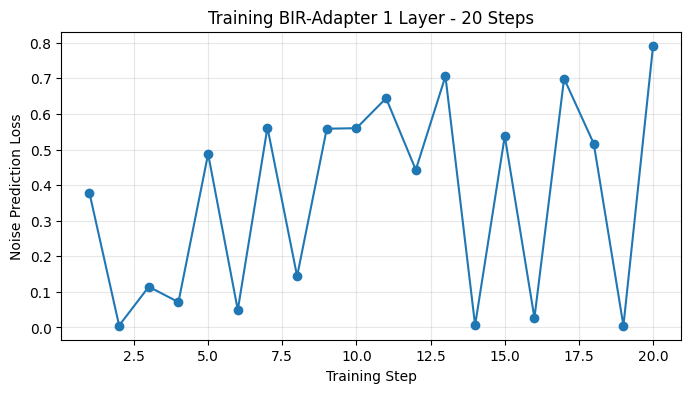

Checkpoint 20 steps berhasil disimpan.


In [67]:

import os
import matplotlib.pyplot as plt

loss_history_42 = []

def training_hook_42(module, inputs, output):
    features = inputs[0]

    degraded = features[0:1]
    diffusion = features[1:2]

    query = module.to_q(degraded).float()

    correction = bir_adapter_v2(
        query,
        diffusion.float()
    )

    return output + correction.to(output.dtype)


hook_42 = attention_layer.register_forward_hook(
    training_hook_42
)

print("=== TRAINING 20 STEPS ===")

try:
    for step in range(1, 21):
        optimizer_bir_real.zero_grad(set_to_none=True)

        timestep_train = torch.randint(
            0, 1000, (1,),
            device=device,
            dtype=torch.long
        )

        noise_train = torch.randn_like(clean_latent_256)

        noisy_clean = train_scheduler.add_noise(
            clean_latent_256,
            noise_train,
            timestep_train
        )

        batch_latents = torch.cat([
            blur_latent_256,
            noisy_clean
        ], dim=0)

        batch_timesteps = timestep_train.repeat(2)

        batch_text = empty_embeddings.repeat(
            2, 1, 1
        )

        # Hanya adapter yang memiliki parameter trainable
        predicted_noise = unet(
            batch_latents,
            batch_timesteps,
            encoder_hidden_states=batch_text
        ).sample[1:2]

        loss = F.mse_loss(
            predicted_noise.float(),
            noise_train.float()
        )

        scaler_bir.scale(loss).backward()
        scaler_bir.unscale_(optimizer_bir_real)

        grad_norm = torch.nn.utils.clip_grad_norm_(
            bir_adapter_v2.parameters(),
            max_norm=1.0
        )

        scaler_bir.step(optimizer_bir_real)
        scaler_bir.update()

        loss_history_42.append(loss.item())

        if step == 1 or step % 5 == 0:
            print(
                f"Step {step:02d}/20 | "
                f"Loss: {loss.item():.6f} | "
                f"Grad: {grad_norm.item():.6f}"
            )

finally:
    hook_42.remove()
    print("Hook training dilepas.")

# Simpan checkpoint
os.makedirs("hasil_bir_adapter", exist_ok=True)

torch.save({
    "adapter_state_dict": bir_adapter_v2.state_dict(),
    "training_steps": 20,
    "prompt": "",
    "attention_layer": self_attention_layers[0][0],
    "loss_history": loss_history_42
}, "hasil_bir_adapter/bir_adapter_1layer_20steps.pth")

# Grafik loss
plt.figure(figsize=(8, 4))
plt.plot(
    range(1, len(loss_history_42) + 1),
    loss_history_42,
    marker="o"
)
plt.xlabel("Training Step")
plt.ylabel("Noise Prediction Loss")
plt.title("Training BIR-Adapter 1 Layer - 20 Steps")
plt.grid(alpha=0.3)
plt.show()

print("Checkpoint 20 steps berhasil disimpan.")


In [68]:

import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

unet.eval()
bir_adapter_v2.eval()

# Menggunakan seed tetap
generator = torch.Generator(
    device=device
).manual_seed(2026)

evaluation_results = []

def hook_eval_43(module, inputs, output):
    features = inputs[0]

    degraded = features[0:1]
    diffusion = features[1:2]

    query = module.to_q(degraded).float()

    correction = bir_adapter_v2(
        query,
        diffusion.float()
    )

    return output + correction.to(output.dtype)


print("=== EVALUASI SETELAH 20 STEPS ===")

for i in range(10):
    timestep_test = torch.randint(
        50, 950, (1,),
        device=device,
        generator=generator,
        dtype=torch.long
    )

    noise_test = torch.randn(
        clean_latent_256.shape,
        device=device,
        dtype=clean_latent_256.dtype,
        generator=generator
    )

    noisy_clean_test = train_scheduler.add_noise(
        clean_latent_256,
        noise_test,
        timestep_test
    )

    batch_latents = torch.cat([
        blur_latent_256,
        noisy_clean_test
    ], dim=0)

    batch_timesteps = timestep_test.repeat(2)

    batch_text = empty_embeddings.repeat(2, 1, 1)

    # A. Tanpa adapter
    with torch.no_grad():
        pred_original = unet(
            batch_latents,
            batch_timesteps,
            encoder_hidden_states=batch_text
        ).sample[1:2]

    # B. Dengan adapter
    handle = attention_layer.register_forward_hook(
        hook_eval_43
    )

    try:
        with torch.no_grad():
            pred_adapter = unet(
                batch_latents,
                batch_timesteps,
                encoder_hidden_states=batch_text
            ).sample[1:2]
    finally:
        handle.remove()

    loss_original = F.mse_loss(
        pred_original.float(),
        noise_test.float()
    ).item()

    loss_adapter = F.mse_loss(
        pred_adapter.float(),
        noise_test.float()
    ).item()

    evaluation_results.append({
        "timestep": timestep_test.item(),
        "original": loss_original,
        "adapter": loss_adapter
    })

    print(
        f"Uji {i+1:02d} | "
        f"t={timestep_test.item():03d} | "
        f"Original={loss_original:.6f} | "
        f"Adapter={loss_adapter:.6f}"
    )

mean_original = np.mean([
    r["original"] for r in evaluation_results
])

mean_adapter = np.mean([
    r["adapter"] for r in evaluation_results
])

better_count = sum(
    r["adapter"] < r["original"]
    for r in evaluation_results
)

improvement = (
    (mean_original - mean_adapter)
    / mean_original
) * 100

print("\n=== RINGKASAN TAHAP 43 ===")
print("Rata-rata tanpa adapter:", mean_original)
print("Rata-rata dengan adapter:", mean_adapter)
print("Adapter lebih baik:", better_count, "dari 10")
print("Perubahan loss (%):", round(improvement, 4))


=== EVALUASI SETELAH 20 STEPS ===
Uji 01 | t=653 | Original=0.071474 | Adapter=0.071047
Uji 02 | t=129 | Original=0.618817 | Adapter=0.615389
Uji 03 | t=403 | Original=0.257714 | Adapter=0.257075
Uji 04 | t=782 | Original=0.035615 | Adapter=0.035451
Uji 05 | t=932 | Original=0.005397 | Adapter=0.005397
Uji 06 | t=632 | Original=0.089608 | Adapter=0.088391
Uji 07 | t=381 | Original=0.283206 | Adapter=0.281007
Uji 08 | t=513 | Original=0.155440 | Adapter=0.154722
Uji 09 | t=394 | Original=0.268824 | Adapter=0.267696
Uji 10 | t=623 | Original=0.090941 | Adapter=0.089729

=== RINGKASAN TAHAP 43 ===
Rata-rata tanpa adapter: 0.18770369114354252
Rata-rata dengan adapter: 0.1865903098601848
Adapter lebih baik: 9 dari 10
Perubahan loss (%): 0.5932


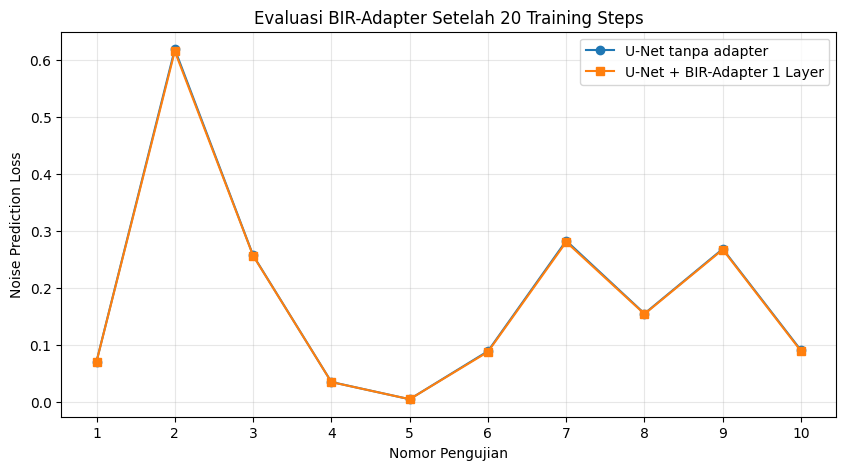

In [69]:

test_numbers = np.arange(1, len(evaluation_results) + 1)

original_losses = [
    r["original"] for r in evaluation_results
]

adapter_losses = [
    r["adapter"] for r in evaluation_results
]

plt.figure(figsize=(10, 5))

plt.plot(
    test_numbers,
    original_losses,
    marker="o",
    label="U-Net tanpa adapter"
)

plt.plot(
    test_numbers,
    adapter_losses,
    marker="s",
    label="U-Net + BIR-Adapter 1 Layer"
)

plt.xlabel("Nomor Pengujian")
plt.ylabel("Noise Prediction Loss")
plt.title("Evaluasi BIR-Adapter Setelah 20 Training Steps")
plt.xticks(test_numbers)
plt.legend()
plt.grid(alpha=0.3)
plt.show()


=== ANALISIS TAHAP 44 ===
Uji 01 | Perbaikan loss: +0.00042704
Uji 02 | Perbaikan loss: +0.00342822
Uji 03 | Perbaikan loss: +0.00063914
Uji 04 | Perbaikan loss: +0.00016420
Uji 05 | Perbaikan loss: -0.00000017
Uji 06 | Perbaikan loss: +0.00121697
Uji 07 | Perbaikan loss: +0.00219956
Uji 08 | Perbaikan loss: +0.00071846
Uji 09 | Perbaikan loss: +0.00112796
Uji 10 | Perbaikan loss: +0.00121243

=== RINGKASAN ===
Rata-rata loss asli: 0.18770369114354252
Rata-rata loss adapter: 0.1865903098601848
Rata-rata selisih: 0.0011133812833577395
Adapter lebih baik: 9 dari 10
Perubahan rata-rata (%): 0.5932


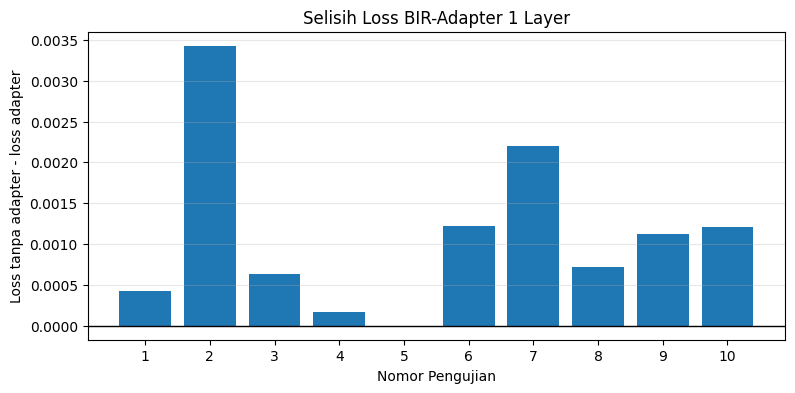

In [70]:

import numpy as np
import matplotlib.pyplot as plt

# Menggunakan hasil evaluasi Tahap 43
original = np.array([
    r["original"] for r in evaluation_results
])

adapter = np.array([
    r["adapter"] for r in evaluation_results
])

# Nilai positif = adapter lebih baik
difference = original - adapter

print("=== ANALISIS TAHAP 44 ===")

for i, diff in enumerate(difference, 1):
    print(
        f"Uji {i:02d} | "
        f"Perbaikan loss: {diff:+.8f}"
    )

print("\n=== RINGKASAN ===")
print("Rata-rata loss asli:", original.mean())
print("Rata-rata loss adapter:", adapter.mean())
print("Rata-rata selisih:", difference.mean())

print(
    "Adapter lebih baik:",
    np.sum(difference > 0),
    "dari",
    len(difference)
)

print(
    "Perubahan rata-rata (%):",
    round(
        difference.mean() / original.mean() * 100,
        4
    )
)

# Grafik khusus untuk melihat selisih
plt.figure(figsize=(9, 4))

plt.bar(
    range(1, len(difference) + 1),
    difference
)

plt.axhline(0, color="black", linewidth=1)
plt.xlabel("Nomor Pengujian")
plt.ylabel("Loss tanpa adapter - loss adapter")
plt.title("Selisih Loss BIR-Adapter 1 Layer")
plt.xticks(range(1, len(difference) + 1))
plt.grid(axis="y", alpha=0.3)
plt.show()


In [71]:

import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from diffusers import DDIMScheduler

unet.eval()
vae.eval()
bir_adapter_v2.eval()

# Scheduler DDIM menggunakan konfigurasi noise training
ddim = DDIMScheduler.from_config(
    train_scheduler.config
)

ddim.set_timesteps(20, device=device)

# Mulai dari bagian tengah proses diffusion
strength = 0.45
start_idx = int(
    len(ddim.timesteps) * (1 - strength)
)

sampling_timesteps = ddim.timesteps[start_idx:]

# Hanya gambar CCTV blur, TIDAK menggunakan clean_latent
generator_45 = torch.Generator(
    device=device
).manual_seed(123)

initial_noise = torch.randn(
    blur_latent_256.shape,
    device=device,
    dtype=blur_latent_256.dtype,
    generator=generator_45
)

initial_latent = ddim.add_noise(
    blur_latent_256,
    initial_noise,
    sampling_timesteps[0:1]
).float()

print("=== PERSIAPAN INFERENSI ===")
print("Input CCTV blur:", blur_latent_256.shape)
print("Latent awal:", initial_latent.shape)
print("Jumlah denoising step:", len(sampling_timesteps))
print("Timestep awal:", sampling_timesteps[0].item())
print("Menggunakan gambar asli: Tidak")


=== PERSIAPAN INFERENSI ===
Input CCTV blur: torch.Size([1, 4, 32, 32])
Latent awal: torch.Size([1, 4, 32, 32])
Jumlah denoising step: 9
Timestep awal: 400
Menggunakan gambar asli: Tidak


In [72]:

import os

attention_layer = self_attention_layers[0][1]

def inference_hook_45(module, inputs, output):
    features = inputs[0]

    # Fitur dari gambar CCTV blur
    degraded = features[0:1]

    # Fitur dari latent yang sedang di-denoise
    diffusion = features[1:2]

    query = module.to_q(degraded).float()

    correction = bir_adapter_v2(
        query,
        diffusion.float()
    )

    return output + correction.to(output.dtype)


def run_sampling_45(use_adapter=False):

    # Mulai dari latent identik untuk perbandingan adil
    latent = initial_latent.clone()

    handle = None

    if use_adapter:
        handle = attention_layer.register_forward_hook(
            inference_hook_45
        )

    try:
        with torch.no_grad():
            for i, t in enumerate(sampling_timesteps):

                # Jalur 1: CCTV blur sebagai kondisi
                # Jalur 2: latent yang sedang di-restorasi
                batch_latents = torch.cat([
                    blur_latent_256,
                    latent.to(unet_dtype)
                ], dim=0)

                batch_text = empty_embeddings.repeat(
                    2, 1, 1
                )

                batch_timesteps = torch.tensor(
                    [t.item(), t.item()],
                    device=device,
                    dtype=torch.long
                )

                predicted_noise = unet(
                    batch_latents,
                    batch_timesteps,
                    encoder_hidden_states=batch_text
                ).sample[1:2]

                # Satu langkah reverse diffusion
                latent = ddim.step(
                    predicted_noise.float(),
                    t,
                    latent.float()
                ).prev_sample

            return latent.detach()

    finally:
        if handle is not None:
            handle.remove()


print("Menjalankan baseline...")
latent_baseline_45 = run_sampling_45(
    use_adapter=False
)

print("Menjalankan adapter 1 layer...")
latent_adapter_45 = run_sampling_45(
    use_adapter=True
)

print("\n=== HASIL SAMPLING ===")
print("Baseline:", latent_baseline_45.shape)
print("Adapter:", latent_adapter_45.shape)

print(
    "Selisih latent:",
    (latent_baseline_45 - latent_adapter_45)
    .abs().mean().item()
)

print(
    "Output finite:",
    torch.isfinite(latent_adapter_45).all().item()
)


Menjalankan baseline...
Menjalankan adapter 1 layer...

=== HASIL SAMPLING ===
Baseline: torch.Size([1, 4, 32, 32])
Adapter: torch.Size([1, 4, 32, 32])
Selisih latent: 0.0076313866302371025
Output finite: True


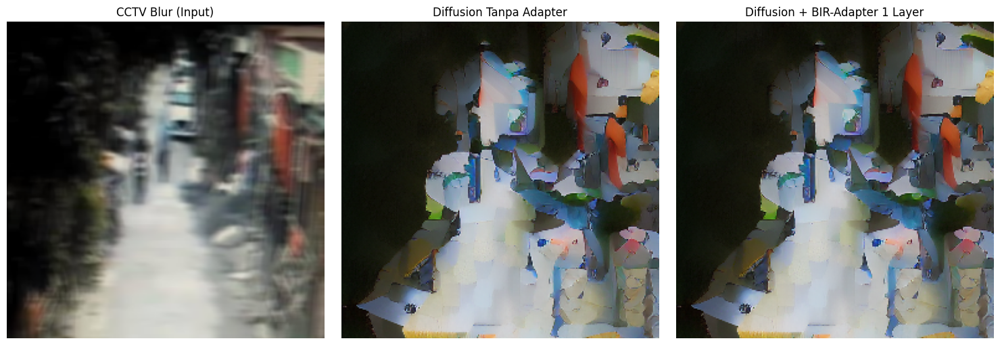

Gambar hasil inferensi berhasil disimpan!


In [73]:

def decode_latent_45(latent):
    with torch.no_grad():
        decoded = vae.decode(
            latent.to(vae_dtype)
            / vae.config.scaling_factor
        ).sample

    decoded = (
        decoded.float().clamp(-1, 1) + 1
    ) / 2

    image = decoded[0].permute(
        1, 2, 0
    ).cpu().numpy()

    return np.clip(
        image * 255, 0, 255
    ).astype(np.uint8)


baseline_img_45 = decode_latent_45(
    latent_baseline_45
)

adapter_img_45 = decode_latent_45(
    latent_adapter_45
)

blur_img_45 = np.array(
    Image.open("cctv_blur.png")
    .convert("RGB")
    .resize((256, 256))
)

# Simpan hasil gambar
os.makedirs("hasil_bir_adapter", exist_ok=True)

Image.fromarray(baseline_img_45).save(
    "hasil_bir_adapter/cctv_baseline_45.png"
)

Image.fromarray(adapter_img_45).save(
    "hasil_bir_adapter/cctv_adapter_1layer_45.png"
)

# Visualisasi
fig, axes = plt.subplots(
    1, 3, figsize=(15, 5)
)

images = [
    blur_img_45,
    baseline_img_45,
    adapter_img_45
]

titles = [
    "CCTV Blur (Input)",
    "Diffusion Tanpa Adapter",
    "Diffusion + BIR-Adapter 1 Layer"
]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Gambar hasil inferensi berhasil disimpan!")


Clip sample DDIM lama: True


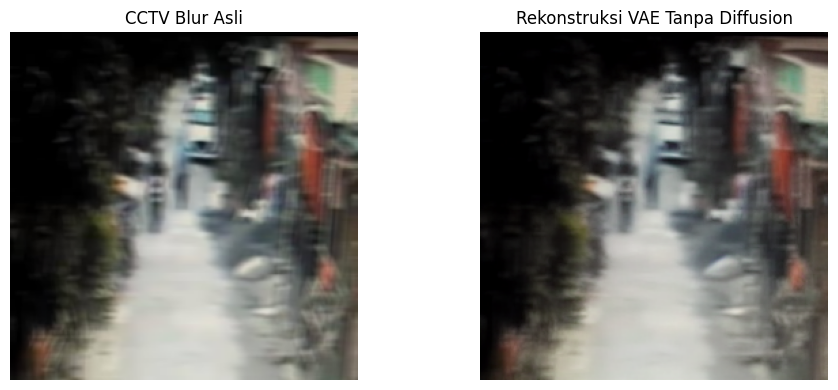

In [74]:

import matplotlib.pyplot as plt
import numpy as np

# Melihat konfigurasi scheduler sebelumnya
print("Clip sample DDIM lama:", ddim.config.clip_sample)

# Rekonstruksi langsung tanpa diffusion
vae_reconstruction = decode_latent_45(
    blur_latent_256.float()
)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(blur_img_45)
plt.title("CCTV Blur Asli")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(vae_reconstruction)
plt.title("Rekonstruksi VAE Tanpa Diffusion")
plt.axis("off")

plt.tight_layout()
plt.show()


=== HASIL TAHAP 46 ===
Clip sample: False
Jumlah denoising step: 5
Selisih latent baseline-adapter: 0.0015165151562541723
Output finite: True


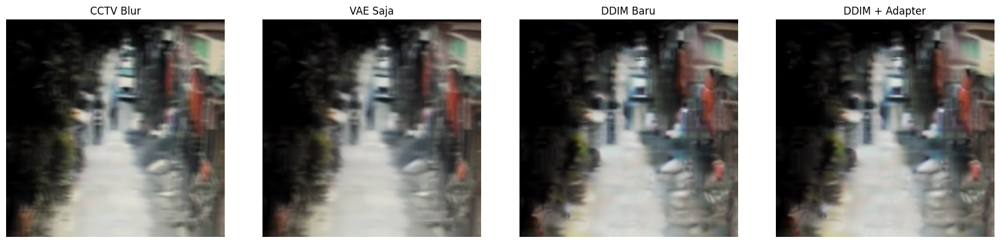

In [75]:

from diffusers import DDIMScheduler
import torch

# Scheduler khusus uji inferensi
ddim_46 = DDIMScheduler.from_config(
    train_scheduler.config,
    clip_sample=False,
    set_alpha_to_one=False,
    steps_offset=1
)

ddim_46.set_timesteps(50, device=device)

strength_46 = 0.10
num_steps_46 = max(
    1,
    int(50 * strength_46)
)

timesteps_46 = ddim_46.timesteps[-num_steps_46:]

# Noise tetap untuk pengujian
generator_46 = torch.Generator(
    device=device
).manual_seed(123)

noise_46 = torch.randn(
    blur_latent_256.shape,
    generator=generator_46,
    device=device,
    dtype=torch.float32
)

initial_46 = ddim_46.add_noise(
    blur_latent_256.float(),
    noise_46,
    timesteps_46[0:1]
)

def run_sampling_46(use_adapter=False):
    latent = initial_46.clone()

    handle = None

    if use_adapter:
        handle = attention_layer.register_forward_hook(
            inference_hook_45
        )

    try:
        with torch.no_grad():
            for t in timesteps_46:
                batch = torch.cat([
                    blur_latent_256,
                    latent.to(unet_dtype)
                ], dim=0)

                batch_t = torch.full(
                    (2,),
                    int(t.item()),
                    device=device,
                    dtype=torch.long
                )

                noise_pred = unet(
                    batch,
                    batch_t,
                    encoder_hidden_states=empty_embeddings.repeat(
                        2, 1, 1
                    )
                ).sample[1:2]

                latent = ddim_46.step(
                    noise_pred.float(),
                    t,
                    latent.float()
                ).prev_sample

        return latent.detach()

    finally:
        if handle is not None:
            handle.remove()


latent_baseline_46 = run_sampling_46(False)
latent_adapter_46 = run_sampling_46(True)

baseline_img_46 = decode_latent_45(latent_baseline_46)
adapter_img_46 = decode_latent_45(latent_adapter_46)

print("=== HASIL TAHAP 46 ===")
print("Clip sample:", ddim_46.config.clip_sample)
print("Jumlah denoising step:", len(timesteps_46))
print(
    "Selisih latent baseline-adapter:",
    (latent_baseline_46 - latent_adapter_46)
    .abs().mean().item()
)
print(
    "Output finite:",
    torch.isfinite(latent_adapter_46).all().item()
)

fig, axes = plt.subplots(1, 4, figsize=(17, 4))

gambar = [
    blur_img_45,
    vae_reconstruction,
    baseline_img_46,
    adapter_img_46
]

judul = [
    "CCTV Blur",
    "VAE Saja",
    "DDIM Baru",
    "DDIM + Adapter"
]

for ax, img, title in zip(axes, gambar, judul):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [76]:

import numpy as np
from PIL import Image
from skimage.metrics import (
    peak_signal_noise_ratio,
    structural_similarity
)

# Gambar referensi asli, disesuaikan ke 256 x 256
clean_reference = np.array(
    Image.open("cctv.jpg")
    .convert("RGB")
    .resize((256, 256), Image.Resampling.LANCZOS)
)

# Semua gambar yang sudah dibuat pada Tahap 46
images_to_evaluate = {
    "CCTV Blur": blur_img_45,
    "VAE Saja": vae_reconstruction,
    "DDIM Tanpa Adapter": baseline_img_46,
    "DDIM + Adapter": adapter_img_46
}

metrics_47 = {}

print("=== EVALUASI PSNR DAN SSIM ===")

for name, image in images_to_evaluate.items():
    image = np.asarray(image, dtype=np.uint8)

    assert image.shape == clean_reference.shape, (
        f"Ukuran {name} tidak sesuai"
    )

    psnr = peak_signal_noise_ratio(
        clean_reference,
        image,
        data_range=255
    )

    ssim = structural_similarity(
        clean_reference,
        image,
        data_range=255,
        channel_axis=-1
    )

    metrics_47[name] = {
        "PSNR": psnr,
        "SSIM": ssim
    }

    print(
        f"{name:22s} | "
        f"PSNR: {psnr:.4f} dB | "
        f"SSIM: {ssim:.4f}"
    )

# Membandingkan adapter dengan baseline diffusion
psnr_difference = (
    metrics_47["DDIM + Adapter"]["PSNR"]
    - metrics_47["DDIM Tanpa Adapter"]["PSNR"]
)

ssim_difference = (
    metrics_47["DDIM + Adapter"]["SSIM"]
    - metrics_47["DDIM Tanpa Adapter"]["SSIM"]
)

print("\n=== PERUBAHAN AKIBAT ADAPTER ===")
print(f"Selisih PSNR: {psnr_difference:+.4f} dB")
print(f"Selisih SSIM: {ssim_difference:+.6f}")


=== EVALUASI PSNR DAN SSIM ===
CCTV Blur              | PSNR: 23.2515 dB | SSIM: 0.6579
VAE Saja               | PSNR: 23.0094 dB | SSIM: 0.6429
DDIM Tanpa Adapter     | PSNR: 21.8036 dB | SSIM: 0.5813
DDIM + Adapter         | PSNR: 21.8057 dB | SSIM: 0.5814

=== PERUBAHAN AKIBAT ADAPTER ===
Selisih PSNR: +0.0022 dB
Selisih SSIM: +0.000117


=== GUIDANCE MAP ===
Ukuran: torch.Size([1, 1, 32, 32])
Minimum: 0.0
Maksimum: 0.9999994039535522
Rata-rata: 0.9067813158035278


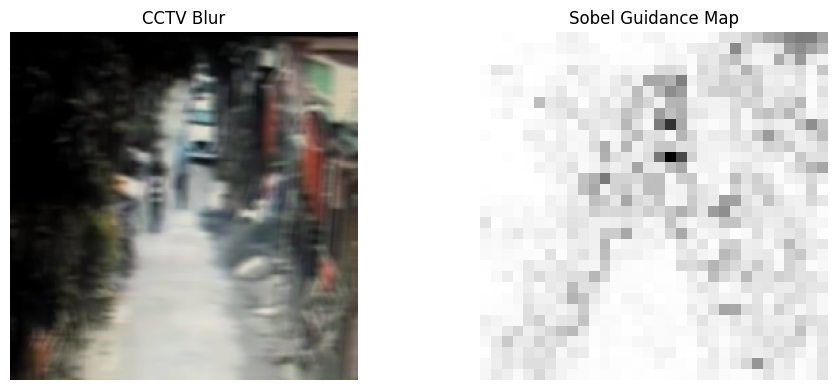

In [77]:

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# Gambar CCTV blur, rentang nilai 0 sampai 1
blur_gray = (
    blur_image_256.float().mean(dim=1, keepdim=True) + 1
) / 2

# Kernel Sobel horizontal
sobel_x = torch.tensor([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], device=device, dtype=torch.float32).view(1, 1, 3, 3)

# Kernel Sobel vertikal
sobel_y = torch.tensor([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
], device=device, dtype=torch.float32).view(1, 1, 3, 3)

# Menghitung gradien gambar
grad_x = F.conv2d(blur_gray, sobel_x, padding=1)
grad_y = F.conv2d(blur_gray, sobel_y, padding=1)

gradient = torch.sqrt(
    grad_x.square() + grad_y.square() + 1e-12
)

# Sesuaikan dengan ukuran latent 32 x 32
gradient_small = F.interpolate(
    gradient,
    size=blur_latent_256.shape[-2:],
    mode="bilinear",
    align_corners=False
)

# Normalisasi
gradient_small = gradient_small / (
    gradient_small.amax(dim=(2, 3), keepdim=True)
    + 1e-8
)

# Bobot panduan: 1 - normalized gradient
guidance_weight_48 = 1.0 - gradient_small

print("=== GUIDANCE MAP ===")
print("Ukuran:", guidance_weight_48.shape)
print("Minimum:", guidance_weight_48.min().item())
print("Maksimum:", guidance_weight_48.max().item())
print("Rata-rata:", guidance_weight_48.mean().item())

# Visualisasi
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(blur_img_45)
axes[0].set_title("CCTV Blur")

axes[1].imshow(
    guidance_weight_48[0, 0].cpu().numpy(),
    cmap="gray",
    vmin=0,
    vmax=1,
    interpolation="nearest"
)
axes[1].set_title("Sobel Guidance Map")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [78]:

import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from skimage.metrics import (
    peak_signal_noise_ratio,
    structural_similarity
)

unet.eval()
bir_adapter_v2.eval()

# Konfigurasi eksperimen
guidance_strength_49 = 0.25
xi_49 = 0.05
T_49 = ddim_46.config.num_train_timesteps

# Peta Sobel yang dibuat pada Tahap 48
weight_49 = guidance_weight_48.to(
    device=device,
    dtype=torch.float32
)

# Referensi guidance:
# menggunakan CCTV blur, bukan gambar clean
reference_latent_49 = blur_latent_256.float()

# Mulai dari latent awal yang sama dengan Tahap 46
latent_49 = initial_46.float().clone()

# Hook adapter satu layer yang sudah dibuat
hook_49 = attention_layer.register_forward_hook(
    inference_hook_45
)

guided_steps_49 = []

try:
    with torch.no_grad():
        for t in timesteps_46:

            t_value = int(t.item())

            # Dua jalur: CCTV blur dan diffusion
            batch_latents = torch.cat([
                blur_latent_256,
                latent_49.to(unet_dtype)
            ], dim=0)

            batch_t = torch.full(
                (2,),
                t_value,
                device=device,
                dtype=torch.long
            )

            noise_pred = unet(
                batch_latents,
                batch_t,
                encoder_hidden_states=empty_embeddings.repeat(
                    2, 1, 1
                )
            ).sample[1:2].float()

            # DDIM biasa
            step_result = ddim_46.step(
                noise_pred,
                t,
                latent_49,
                eta=0.0
            )

            predicted_x0 = step_result.pred_original_sample
            next_latent = step_result.prev_sample

            # Guidance pada timestep tertentu
            if t_value / T_49 > xi_49:

                guided_x0 = predicted_x0 + (
                    guidance_strength_49
                    * weight_49
                    * (reference_latent_49 - predicted_x0)
                )

                # Mengoreksi langkah DDIM berdasarkan
                # perubahan estimasi latent bersih
                prev_t = t_value - (
                    T_49 // ddim_46.num_inference_steps
                )

                if prev_t >= 0:
                    alpha_prev = ddim_46.alphas_cumprod[prev_t]
                else:
                    alpha_prev = ddim_46.final_alpha_cumprod

                alpha_prev = alpha_prev.to(
                    device=device,
                    dtype=torch.float32
                )

                next_latent = next_latent + (
                    alpha_prev.sqrt()
                    * (guided_x0 - predicted_x0)
                )

                guided_steps_49.append(t_value)

            latent_49 = next_latent.detach()

finally:
    hook_49.remove()

print("=== HASIL GUIDED SAMPLING ===")
print("Output:", latent_49.shape)
print("Guidance strength:", guidance_strength_49)
print("Guidance aktif di timestep:", guided_steps_49)
print(
    "Semua nilai finite:",
    torch.isfinite(latent_49).all().item()
)

guided_img_49 = decode_latent_45(latent_49)


=== HASIL GUIDED SAMPLING ===
Output: torch.Size([1, 4, 32, 32])
Guidance strength: 0.25
Guidance aktif di timestep: [81, 61]
Semua nilai finite: True


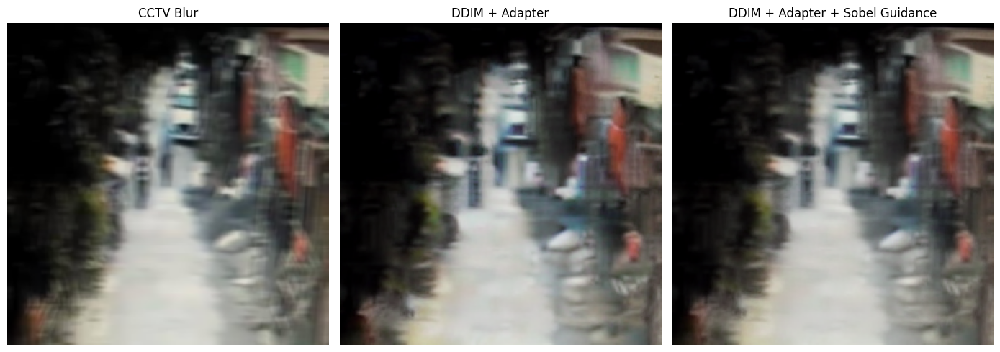


=== EVALUASI TAHAP 49 ===
CCTV Blur                        | PSNR: 23.2515 dB | SSIM: 0.6579
DDIM + Adapter                   | PSNR: 21.8057 dB | SSIM: 0.5814
DDIM + Adapter + Sobel Guidance  | PSNR: 22.4533 dB | SSIM: 0.6153

Gambar guided sampling berhasil disimpan.


In [79]:

# Perbandingan gambar
fig, axes = plt.subplots(1, 3, figsize=(14, 5))

images_49 = [
    blur_img_45,
    adapter_img_46,
    guided_img_49
]

titles_49 = [
    "CCTV Blur",
    "DDIM + Adapter",
    "DDIM + Adapter + Sobel Guidance"
]

for ax, img, title in zip(axes, images_49, titles_49):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

# Evaluasi terhadap gambar asli
print("\n=== EVALUASI TAHAP 49 ===")

for name, img in zip(titles_49, images_49):

    psnr = peak_signal_noise_ratio(
        clean_reference,
        img,
        data_range=255
    )

    ssim = structural_similarity(
        clean_reference,
        img,
        data_range=255,
        channel_axis=-1
    )

    print(
        f"{name:32s} | "
        f"PSNR: {psnr:.4f} dB | "
        f"SSIM: {ssim:.4f}"
    )

# Simpan hasil
import os

os.makedirs("hasil_bir_adapter", exist_ok=True)

Image.fromarray(guided_img_49).save(
    "hasil_bir_adapter/cctv_guided_49.png"
)

print("\nGambar guided sampling berhasil disimpan.")


In [80]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from skimage.restoration import richardson_lucy
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

# Pakai resolusi 256 agar konsisten dengan eksperimen diffusion
clean_50 = np.array(
    Image.open("cctv.jpg")
    .convert("RGB")
    .resize((256, 256), Image.Resampling.LANCZOS)
)

blur_50 = np.array(
    Image.open("cctv_blur.png")
    .convert("RGB")
    .resize((256, 256), Image.Resampling.LANCZOS)
)

# Kernel motion blur horizontal
k = 21
kernel_50 = np.zeros((k, k), dtype=np.float32)
kernel_50[k // 2, :] = 1.0 / k

blur_float_50 = blur_50.astype(np.float32) / 255.0

iterations_list = [3, 5, 10, 15]
results_50 = []

print("=== KANDIDAT INITIAL RESTORATION ===")

for num_iter in iterations_list:
    restored_channels = []

    for c in range(3):
        restored_c = richardson_lucy(
            blur_float_50[:, :, c],
            kernel_50,
            num_iter=num_iter,
            clip=True
        )
        restored_channels.append(restored_c)

    restored = np.stack(restored_channels, axis=2)
    restored = np.clip(restored, 0, 1)
    restored_uint8 = (restored * 255).astype(np.uint8)

    psnr_val = peak_signal_noise_ratio(
        clean_50,
        restored_uint8,
        data_range=255
    )

    ssim_val = structural_similarity(
        clean_50,
        restored_uint8,
        data_range=255,
        channel_axis=-1
    )

    results_50.append({
        "iter": num_iter,
        "image": restored_uint8,
        "psnr": psnr_val,
        "ssim": ssim_val
    })

    print(
        f"Iterasi {num_iter:2d} | "
        f"PSNR: {psnr_val:.4f} dB | "
        f"SSIM: {ssim_val:.4f}"
    )

# Baseline blur
psnr_blur_50 = peak_signal_noise_ratio(
    clean_50, blur_50, data_range=255
)

ssim_blur_50 = structural_similarity(
    clean_50, blur_50,
    data_range=255,
    channel_axis=-1
)

print("\n=== BASELINE ===")
print(f"Blur | PSNR: {psnr_blur_50:.4f} dB | SSIM: {ssim_blur_50:.4f}")

=== KANDIDAT INITIAL RESTORATION ===
Iterasi  3 | PSNR: 20.6268 dB | SSIM: 0.5387
Iterasi  5 | PSNR: 19.6646 dB | SSIM: 0.5169
Iterasi 10 | PSNR: 17.8833 dB | SSIM: 0.4606
Iterasi 15 | PSNR: 16.9299 dB | SSIM: 0.4152

=== BASELINE ===
Blur | PSNR: 23.2502 dB | SSIM: 0.6580


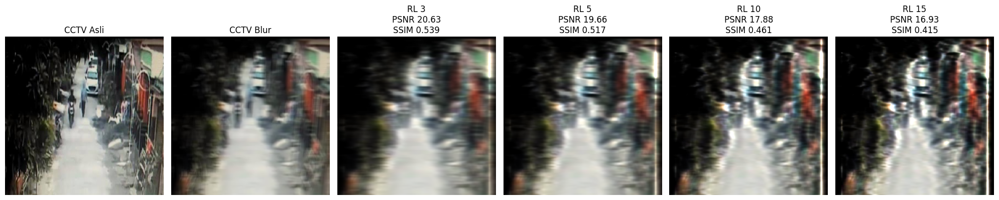

In [81]:
fig, axes = plt.subplots(1, 2 + len(results_50), figsize=(20, 4))

axes[0].imshow(clean_50)
axes[0].set_title("CCTV Asli")
axes[0].axis("off")

axes[1].imshow(blur_50)
axes[1].set_title("CCTV Blur")
axes[1].axis("off")

for ax, result in zip(axes[2:], results_50):
    ax.imshow(result["image"])
    ax.set_title(
        f"RL {result['iter']}\n"
        f"PSNR {result['psnr']:.2f}\n"
        f"SSIM {result['ssim']:.3f}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

=== HASIL PILIHAN ===
Iterasi terbaik: 3
PSNR terbaik: 20.6268 dB
SSIM terbaik: 0.5387


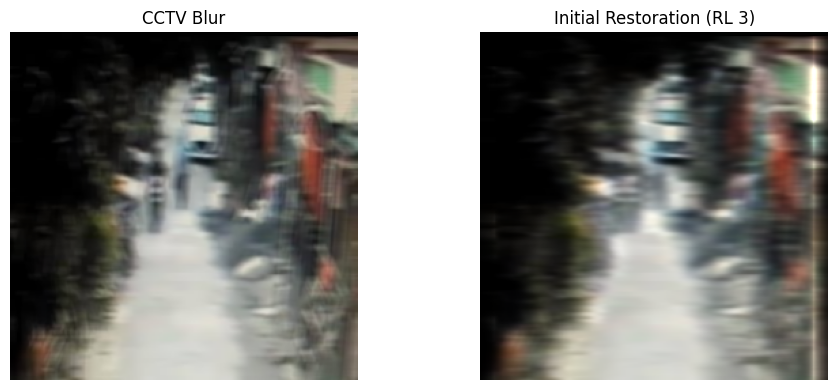

In [82]:
best_result_50 = max(results_50, key=lambda x: x["ssim"])

initial_restoration_50 = best_result_50["image"]

print("=== HASIL PILIHAN ===")
print("Iterasi terbaik:", best_result_50["iter"])
print(f"PSNR terbaik: {best_result_50['psnr']:.4f} dB")
print(f"SSIM terbaik: {best_result_50['ssim']:.4f}")

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(blur_50)
plt.title("CCTV Blur")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(initial_restoration_50)
plt.title(f"Initial Restoration (RL {best_result_50['iter']})")
plt.axis("off")

plt.tight_layout()
plt.show()

In [83]:
from PIL import Image
import os

os.makedirs("hasil_bir_adapter", exist_ok=True)

initial_restoration_path_50 = "hasil_bir_adapter/initial_restoration_50.png"

Image.fromarray(initial_restoration_50).save(initial_restoration_path_50)

print("Restorasi awal berhasil disimpan di:")
print(initial_restoration_path_50)

Restorasi awal berhasil disimpan di:
hasil_bir_adapter/initial_restoration_50.png


In [84]:
import torch
import numpy as np
from PIL import Image

def load_initial_restoration_for_vae(path):
    image = Image.open(path).convert("RGB")
    image = image.resize((256, 256), Image.Resampling.LANCZOS)

    image = np.asarray(image).astype("float32")
    image = image / 127.5 - 1.0

    tensor = torch.from_numpy(image).permute(2, 0, 1).unsqueeze(0)

    return tensor.to(device=device, dtype=vae_dtype)

initial_restoration_tensor_50 = load_initial_restoration_for_vae(
    initial_restoration_path_50
)

with torch.no_grad():
    initial_restoration_latent_50 = (
        vae.encode(initial_restoration_tensor_50).latent_dist.mode()
        * vae.config.scaling_factor
    )

print("=== LATENT RESTORASI AWAL ===")
print("Tensor gambar:", initial_restoration_tensor_50.shape)
print("Latent:", initial_restoration_latent_50.shape)

=== LATENT RESTORASI AWAL ===
Tensor gambar: torch.Size([1, 3, 256, 256])
Latent: torch.Size([1, 4, 32, 32])


In [85]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

# Pastikan variabel ini sudah ada dari tahap sebelumnya:
# clean_50
# blur_50
# initial_restoration_50   # RL 3 terbaik

alphas_51 = [0.1, 0.2, 0.3, 0.4]
blend_results_51 = []

print("=== BLENDED INITIAL RESTORATION ===")

for alpha in alphas_51:
    blended = (
        (1 - alpha) * blur_50.astype(np.float32)
        + alpha * initial_restoration_50.astype(np.float32)
    )

    blended = np.clip(blended, 0, 255).astype(np.uint8)

    psnr_val = peak_signal_noise_ratio(
        clean_50, blended, data_range=255
    )

    ssim_val = structural_similarity(
        clean_50, blended,
        data_range=255,
        channel_axis=-1
    )

    blend_results_51.append({
        "alpha": alpha,
        "image": blended,
        "psnr": psnr_val,
        "ssim": ssim_val
    })

    print(
        f"Alpha {alpha:.1f} | "
        f"PSNR: {psnr_val:.4f} dB | "
        f"SSIM: {ssim_val:.4f}"
    )

=== BLENDED INITIAL RESTORATION ===
Alpha 0.1 | PSNR: 23.1307 dB | SSIM: 0.6513
Alpha 0.2 | PSNR: 22.9698 dB | SSIM: 0.6431
Alpha 0.3 | PSNR: 22.7634 dB | SSIM: 0.6331
Alpha 0.4 | PSNR: 22.5220 dB | SSIM: 0.6218


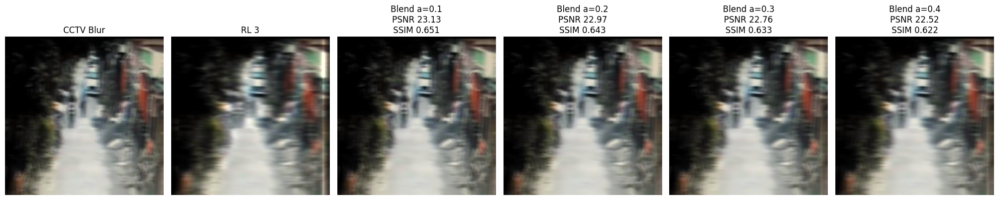

In [86]:
fig, axes = plt.subplots(1, 2 + len(blend_results_51), figsize=(20, 4))

axes[0].imshow(blur_50)
axes[0].set_title("CCTV Blur")
axes[0].axis("off")

axes[1].imshow(initial_restoration_50)
axes[1].set_title("RL 3")
axes[1].axis("off")

for ax, result in zip(axes[2:], blend_results_51):
    ax.imshow(result["image"])
    ax.set_title(
        f"Blend a={result['alpha']}\n"
        f"PSNR {result['psnr']:.2f}\n"
        f"SSIM {result['ssim']:.3f}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

=== HASIL BLEND TERBAIK ===
Alpha terbaik: 0.1
PSNR: 23.1307 dB
SSIM: 0.6513


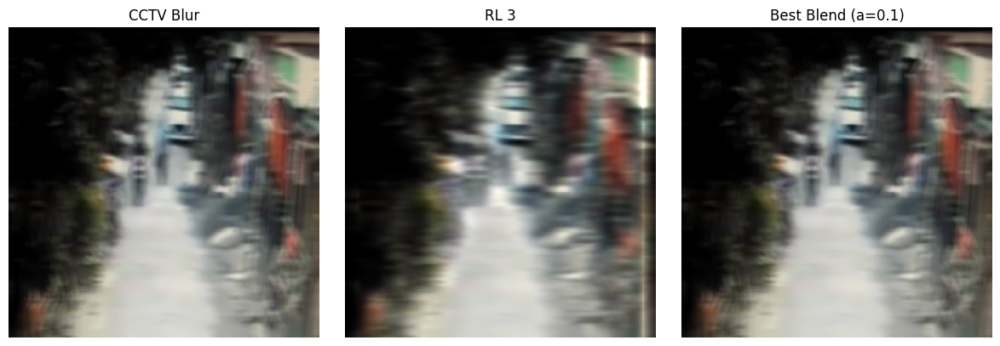

In [87]:
best_blend_51 = max(blend_results_51, key=lambda x: x["ssim"])

best_blend_img_51 = best_blend_51["image"]

print("=== HASIL BLEND TERBAIK ===")
print("Alpha terbaik:", best_blend_51["alpha"])
print(f"PSNR: {best_blend_51['psnr']:.4f} dB")
print(f"SSIM: {best_blend_51['ssim']:.4f}")

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(blur_50)
plt.title("CCTV Blur")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(initial_restoration_50)
plt.title("RL 3")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(best_blend_img_51)
plt.title(f"Best Blend (a={best_blend_51['alpha']})")
plt.axis("off")

plt.tight_layout()
plt.show()

In [88]:
import os
import torch
import numpy as np
from PIL import Image

os.makedirs("hasil_bir_adapter", exist_ok=True)

best_blend_path_51 = "hasil_bir_adapter/best_blend_51.png"
Image.fromarray(best_blend_img_51).save(best_blend_path_51)

def load_rgb_for_vae(path):
    image = Image.open(path).convert("RGB")
    image = image.resize((256, 256), Image.Resampling.LANCZOS)

    image = np.asarray(image).astype("float32")
    image = image / 127.5 - 1.0

    tensor = torch.from_numpy(image).permute(2, 0, 1).unsqueeze(0)
    return tensor.to(device=device, dtype=vae_dtype)

best_blend_tensor_51 = load_rgb_for_vae(best_blend_path_51)

with torch.no_grad():
    best_blend_latent_51 = (
        vae.encode(best_blend_tensor_51).latent_dist.mode()
        * vae.config.scaling_factor
    )

print("=== LATENT BLEND TERBAIK ===")
print("Tensor:", best_blend_tensor_51.shape)
print("Latent:", best_blend_latent_51.shape)

=== LATENT BLEND TERBAIK ===
Tensor: torch.Size([1, 3, 256, 256])
Latent: torch.Size([1, 4, 32, 32])


In [89]:
import torch
import matplotlib.pyplot as plt
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

# guidance map tetap pakai yang sudah dibuat
weight_52 = guidance_weight_48.to(device=device, dtype=torch.float32)

# reference latent baru: hasil blend terbaik
reference_latent_52 = best_blend_latent_51.float()

guidance_strength_52 = 0.25
xi_52 = 0.05
T_52 = ddim_46.config.num_train_timesteps

latent_52 = initial_46.float().clone()

hook_52 = attention_layer.register_forward_hook(
    inference_hook_45
)

guided_steps_52 = []

try:
    with torch.no_grad():
        for t in timesteps_46:
            t_value = int(t.item())

            batch_latents = torch.cat([
                blur_latent_256,
                latent_52.to(unet_dtype)
            ], dim=0)

            batch_t = torch.full(
                (2,),
                t_value,
                device=device,
                dtype=torch.long
            )

            noise_pred = unet(
                batch_latents,
                batch_t,
                encoder_hidden_states=empty_embeddings.repeat(2, 1, 1)
            ).sample[1:2].float()

            step_result = ddim_46.step(
                noise_pred,
                t,
                latent_52,
                eta=0.0
            )

            predicted_x0 = step_result.pred_original_sample
            next_latent = step_result.prev_sample

            if t_value / T_52 > xi_52:
                guided_x0 = predicted_x0 + (
                    guidance_strength_52
                    * weight_52
                    * (reference_latent_52 - predicted_x0)
                )

                prev_t = t_value - (
                    T_52 // ddim_46.num_inference_steps
                )

                if prev_t >= 0:
                    alpha_prev = ddim_46.alphas_cumprod[prev_t]
                else:
                    alpha_prev = ddim_46.final_alpha_cumprod

                alpha_prev = alpha_prev.to(device=device, dtype=torch.float32)

                next_latent = next_latent + (
                    alpha_prev.sqrt() * (guided_x0 - predicted_x0)
                )

                guided_steps_52.append(t_value)

            latent_52 = next_latent.detach()

finally:
    hook_52.remove()

print("=== HASIL TAHAP 52 ===")
print("Output:", latent_52.shape)
print("Guidance aktif di timestep:", guided_steps_52)
print("Finite:", torch.isfinite(latent_52).all().item())

=== HASIL TAHAP 52 ===
Output: torch.Size([1, 4, 32, 32])
Guidance aktif di timestep: [81, 61]
Finite: True


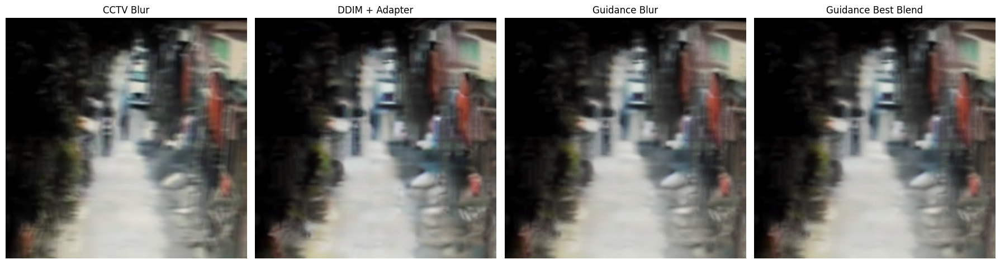

In [90]:
guided_blend_img_52 = decode_latent_45(latent_52)

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

images_52 = [
    blur_img_45,
    adapter_img_46,
    guided_img_49,
    guided_blend_img_52
]

titles_52 = [
    "CCTV Blur",
    "DDIM + Adapter",
    "Guidance Blur",
    "Guidance Best Blend"
]

for ax, img, title in zip(axes, images_52, titles_52):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [91]:
print("=== EVALUASI TAHAP 52 ===")

images_eval_52 = {
    "CCTV Blur": blur_img_45,
    "DDIM + Adapter": adapter_img_46,
    "Guidance Blur": guided_img_49,
    "Guidance Best Blend": guided_blend_img_52
}

for name, img in images_eval_52.items():
    psnr = peak_signal_noise_ratio(
        clean_reference, img, data_range=255
    )
    ssim = structural_similarity(
        clean_reference,
        img,
        data_range=255,
        channel_axis=-1
    )
    print(f"{name:24s} | PSNR: {psnr:.4f} dB | SSIM: {ssim:.4f}")

=== EVALUASI TAHAP 52 ===
CCTV Blur                | PSNR: 23.2515 dB | SSIM: 0.6579
DDIM + Adapter           | PSNR: 21.8057 dB | SSIM: 0.5814
Guidance Blur            | PSNR: 22.4533 dB | SSIM: 0.6153
Guidance Best Blend      | PSNR: 22.4090 dB | SSIM: 0.6130
